# Matplotlib — Plotting in Python

**Definition.** Matplotlib is a comprehensive library for creating static, animated and interactive
visualizations in Python. It is the foundation of the Python plotting ecosystem — `pandas`,
`seaborn` and `plotnine` all draw through it.

### Anatomy of a plot

| Object | What it is |
| --- | --- |
| **Figure** | the whole canvas — the window or image file |
| **Axes** | one individual plot inside the figure, with its own coordinate system (a figure can hold several) |
| **Axis** | a single x or y number line, with its ticks and labels |
| **Artist** | everything drawn — lines, bars, wedges, text, legends |

Note the wording trap: **Axes** (one plot) is not the plural of **Axis** (one number line).

### `pyplot` — the interface used throughout this notebook

`matplotlib.pyplot` is a collection of functions that make Matplotlib work like MATLAB. It keeps
track of a **current figure** and **current axes** for you, so each call — `plt.plot()`,
`plt.xlabel()`, `plt.title()` — quietly modifies that hidden current figure until `plt.show()`
renders it **and clears it**.

```python
import matplotlib.pyplot as plt   # the standard alias
import numpy as np                # used for bin edges, bar offsets and sample data
```

That implicit state is what makes `pyplot` quick for a single chart, and what makes it awkward for
several: the **object-oriented API** is preferred for anything larger, since it names what it draws
on instead of relying on "current". Sections 9 and 10 cover both.

```python
fig, ax = plt.subplots()     # explicit figure and axes
ax.plot(x, y)
ax.set_xlabel('X')
```

Every `plt.foo()` below has an `ax.foo()` or `ax.set_foo()` equivalent, so the two styles translate
directly — **section 10** gives the full translation table.

### The four steps in every plot here

| Step | Functions | What it does |
| --- | --- | --- |
| 1. **Draw** | `plot` · `bar` · `scatter` · `hist` · `pie` · `boxplot` · `stackplot` | put data on the current axes |
| 2. **Describe** | `xlabel` · `ylabel` · `title` · `legend` · `text` · `annotate` · `colorbar` | say what was drawn |
| 3. **Adjust** | `xlim` · `ylim` · `xticks` · `grid` · `style.use` · `tight_layout` | tune the view |
| 4. **Output** | `show` · `savefig` | render to screen or to a file |

Steps 1 and 4 are mandatory; skipping step 2 is what makes a chart unreadable.

### Which chart should I use?

| Your question | Chart | Section |
| --- | --- | --- |
| How does a value change over an ordered axis? | **line** | 1 |
| Which category is biggest? | **bar** | 3 |
| Do two measured quantities move together? | **scatter** | 4 |
| How is one variable distributed? | **histogram** | 5 |
| What share of a total is each part? | **pie** | 6 |
| How do spreads compare across groups? | **box plot** | 7 |
| How did a total *and* its composition change over time? | **stack plot** | 8 |
| How do I show several charts in one figure? | **subplots** | 9, 10 |

### Contents

| § | Topic | What it introduces |
| --- | --- | --- |
| **1** | Line Chart | `plt.plot`, markers, multiple series, `legend` |
| **2** | Format Strings | `'o--g'` shorthand, `style.use`, `grid`, `xkcd`, categorical ticks, `savefig` |
| **3** | Bar Chart | `plt.bar`, value labels with `text`, axis limits, grouped bars via `np.arange` |
| **4** | Scatter Plot | `plt.scatter`, `s`/`c`/`cmap`, `colorbar`, `annotate`, series by category |
| **5** | Histogram | `plt.hist`, choosing `bins`, custom bin edges, `axvline` |
| **6** | Pie Chart | `plt.pie`, `autopct`, `explode`, `wedgeprops`, `startangle` |
| **7** | Box Plot | `plt.boxplot`, the five-number summary, IQR, outliers, group comparison |
| **8** | Stack Plot | `plt.stackplot`, totals vs composition, 100% stacked |
| **9** | Subplots | `plt.subplot(r, c, i)`, grids, `tight_layout` |
| **10** | Object-Oriented API | `fig, ax = plt.subplots()`, `ax.set_*`, computed grids, `ax.flatten` |
|  | Summary | full cheat sheet and the gotchas worth memorising |

### Datasets used

| Data | Sections |
| --- | --- |
| Oscar vs non-Oscar movie revenue, 2010–2015 | 1, 2, 3 |
| Ages and blood pressure of ten people | 4 |
| Seasonal temperature and humidity for five cities | 4.4 |
| Ages of 250 patients (`np.random.normal`) | 5 |
| A monthly household budget | 6 |
| `[7, 8, 5, 6, 9, 4, 10, 12, 15]` and three synthetic groups | 7 |
| A week of website traffic by acquisition channel | 8 |
| Four functions of `x` — root, double, square, cube | 9, 10.1, 10.2 |
| A week of temperatures for five cities | 10.3, 10.4 |

### Two notes on running this notebook

1. **Run the cells in order.** Later cells reuse variables defined earlier (`years`,
   `oscar_revenue`, `patient_ages`, `days`), so jumping in halfway raises `NameError`.
2. **`plt.style.use()` is global.** Section 6 switches to `dark_background`, which then affects
   every figure drawn afterwards. Run `plt.style.use('default')` to get the standard look back.


---
## 1. Line Chart

**Definition.** A line chart connects consecutive data points with straight segments. It is the
default chart for showing how a quantity **changes across an ordered axis** — usually time.

**Usage**

```python
plt.plot(x, y)          # x and y must be the same length
```

**Actions in the cell below**
- `plt.plot(x, y)` — draw the line.
- `plt.xlabel()` / `plt.ylabel()` — name the axes so the numbers mean something.
- `plt.title()` — describe the chart.
- `plt.show()` — render the figure and clear it, ready for the next plot.

**When to use:** ordered / continuous data (years, months, sensor readings).
**When not to:** unordered categories — the connecting line implies a progression that isn't there.


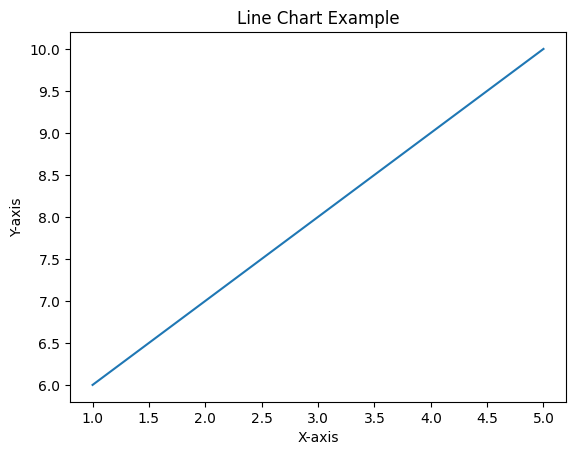

In [3]:
# Line Chart
import matplotlib.pyplot as plt

# Sample data
x = [1, 2, 3, 4, 5]
y = [6, 7, 8, 9, 10]

# Create a line chart
plt.plot(x, y)
plt.xlabel('X-axis')
plt.ylabel('Y-axis')
plt.title('Line Chart Example')
plt.show()

### 1.1 A line chart on real data

**Definition.** Same `plt.plot()` call, now with a meaningful dataset: worldwide box-office revenue
(in millions of USD) of the Best-Picture Oscar winners for 2010–2015.

**Usage**

```python
plt.plot(years, oscar_revenue, marker='o')
```

**Actions**
- `marker='o'` — draw a visible dot at every actual data point. Without it you only see the
  interpolated line and cannot tell where the real observations are.
- The line goes **downward**: prestige winners earned steadily less over these six years.


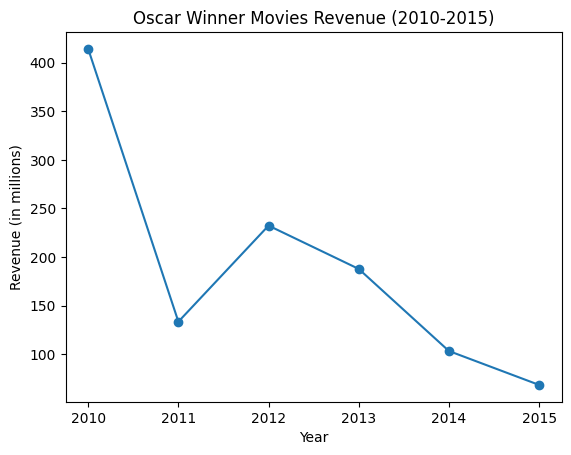

In [4]:
# Real data

# Oscar winner movies from 2010 to 2020
oscar_movies = [
    "The King's Speech",
    "The Artist",
    "Argo",
    "12 Years a Slave",
    "Birdman",
    "Spotlight"
]
years = [2010, 2011, 2012, 2013, 2014, 2015]
oscar_revenue = [414.2, 133.4, 232.3, 187.7, 103.2, 68.3]  # in millions

plt.plot(years, oscar_revenue, marker='o')
plt.xlabel('Year')
plt.ylabel('Revenue (in millions)')
plt.title('Oscar Winner Movies Revenue (2010-2015)')
plt.show()

### 1.2 Two lines on the same axes (comparison + legend)

**Definition.** Because `pyplot` keeps drawing on the *current* axes, calling `plt.plot()` twice
before `plt.show()` layers both series in the same coordinate system — that is how comparisons
are made.

**Usage**

```python
plt.plot(x, y1, color='orange', label='Series A')
plt.plot(x, y2, color='blue',   label='Series B')
plt.legend()      # reads the label= values and draws the key
```

**Actions**
- `color=` — give each series its own colour so they can be told apart.
- `label=` — the text each series gets in the legend.
- `plt.legend()` — **required**; labels alone draw nothing. Optional `loc='upper left'` to place it.

**Watch the y-axis:** adding the blockbuster series rescales it to ~1700, which visually flattens
the Oscar line. Shared axes make comparison honest, but the smaller series loses detail.


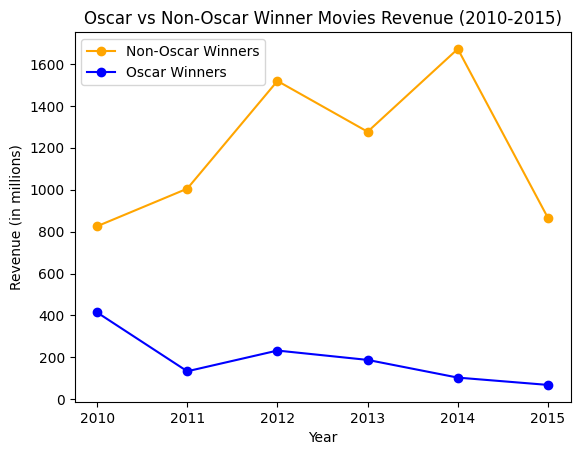

In [5]:
non_oscar_movies = [
    "Inception",
    "The Dark Knight Rises",
    "The Avengers",
    "Frozen",
    "Jurassic World",
    "The Hunger Games: Catching Fire"
]
non_oscar_revenue = [825.5, 1004.9, 1518.8, 1276.5, 1671.7, 865.0]  # in millions

plt.plot(years, non_oscar_revenue, marker='o', color='orange', label='Non-Oscar Winners')
plt.plot(years, oscar_revenue, marker='o', color='blue', label='Oscar Winners')
plt.xlabel('Year')
plt.ylabel('Revenue (in millions)')
plt.title("Oscar vs Non-Oscar Winner Movies Revenue (2010-2015)")
plt.legend()
plt.show()

### Conclusion: The line chart clearly shows that non-Oscar winner movies tend to generate higher revenue compared to Oscar-winning movies over the years 2010 to 2015.

---
## 2. Format Strings — `'[marker][line style][color]'`

**Definition.** A format string is a compact shorthand that replaces the `marker=`, `linestyle=`
and `color=` keyword arguments with a single positional string, e.g. `'o--g'` =
circle markers + dashed line + green.

**Usage**

```python
plt.plot(x, y, 'o--g')                  # shorthand
plt.plot(x, y, marker='o', linestyle='--', color='green')   # identical, explicit
```

| Markers | Line styles | Colors |
| --- | --- | --- |
| `.` point &nbsp;&nbsp; `o` circle | `-` solid | `b` blue &nbsp;&nbsp; `g` green |
| `s` square &nbsp;&nbsp; `^` triangle | `--` dashed | `r` red &nbsp;&nbsp; `c` cyan |
| `*` star &nbsp;&nbsp; `+` plus | `-.` dash-dot | `m` magenta &nbsp;&nbsp; `y` yellow |
| `x` cross &nbsp;&nbsp; `D` diamond | `:` dotted | `k` black &nbsp;&nbsp; `w` white |

**Actions in the cell below**
- `'o--g'` — non-Oscar series as a dashed green line with circle markers.
- `'o-b'` with `linewidth=2` — Oscar series as a thicker solid blue line. Keyword arguments can be
  mixed with a format string; the keyword wins on conflict.

**Note:** order inside the string is flexible (`'g--o'` works), but the parts must be unambiguous —
for anything beyond the 8 single-letter colours use `color='#FF8800'` explicitly.


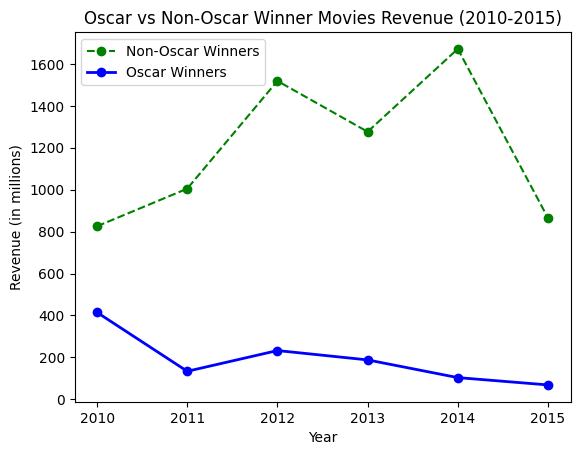

In [6]:

plt.plot(years, non_oscar_revenue,'o--g' , label='Non-Oscar Winners')
plt.plot(years, oscar_revenue, 'o-b',linewidth=2, label='Oscar Winners')
plt.xlabel('Year')
plt.ylabel('Revenue (in millions)')
plt.title("Oscar vs Non-Oscar Winner Movies Revenue (2010-2015)")
plt.legend()
plt.show()

### 2.1 Styles and grid lines

**Definition.** A *style sheet* is a named bundle of default settings (colours, fonts, background,
grid) applied to every subsequent plot. A *grid* draws reference lines at the tick positions so
values can be read off the chart.

**Usage**

```python
plt.style.use('ggplot')     # apply a style sheet
plt.grid()                  # grid lines at the ticks
print(plt.style.available)  # list every installed style
```

Popular styles: `ggplot`, `seaborn-v0_8`, `fivethirtyeight`, `bmh`, `dark_background`, `default`.

**Actions in the cell below**
- `plt.style.use('default')` — reset to Matplotlib's stock look (`'ggplot'` is commented out; swap
  the comments to compare).
- `plt.grid()` — add the reference grid. Refine with `plt.grid(axis='y', alpha=0.3)`.

**Gotcha:** `plt.style.use()` is **global and applies from the next figure onward**, so calling it
after the `plt.plot()` calls (as here) affects later cells more than this one. Set the style once at
the top of a notebook.


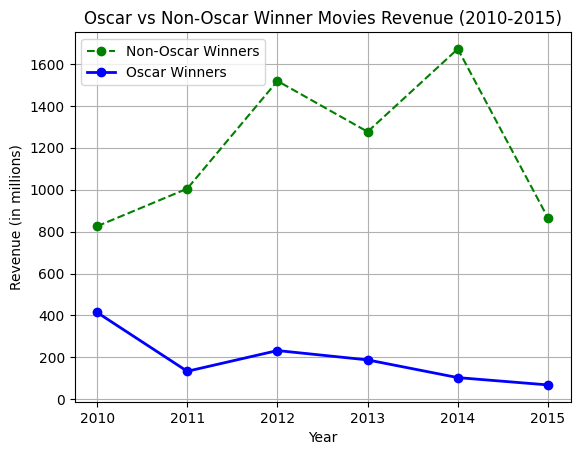

In [7]:


plt.plot(years, non_oscar_revenue,'o--g' , label='Non-Oscar Winners')
plt.plot(years, oscar_revenue, 'o-b',linewidth=2, label='Oscar Winners')
plt.xlabel('Year')
plt.ylabel('Revenue (in millions)')
plt.title("Oscar vs Non-Oscar Winner Movies Revenue (2010-2015)")
plt.legend()
# plt.style.use('ggplot')
plt.style.use('default')
plt.grid()
plt.show()



### 2.2 `plt.xkcd()` — the hand-drawn sketch style *(cell kept commented out)*

**Definition.** `plt.xkcd()` switches on a sketch-style rendering that mimics xkcd comics — wobbly
lines and a handwriting font. Used as a **context manager** it affects only the enclosed block.

**Usage**

```python
with plt.xkcd():
    plt.plot(x, y)
    plt.show()          # outside the with-block everything is back to normal
```

**Actions / notes**
- Useful for informal, deliberately "rough" charts where precision would be over-claiming.
- It needs the *Humor Sans* font; without it Matplotlib emits font warnings and falls back — which
  is why this cell is left commented out.
- Never use it in a report or anything numeric-critical.


In [8]:
# with plt.xkcd():
#     plt.plot(years, non_oscar_revenue,'o--g' , label='Non-Oscar Winners')
#     plt.plot(years, oscar_revenue, 'o-b',linewidth=2, label='Oscar Winners')
#     plt.xlabel('Year')
#     plt.ylabel('Revenue (in millions)')
#     plt.title("Oscar vs Non-Oscar Winner Movies Revenue (2010-2015)")
#     plt.legend()
#     # plt.style.use('ggplot')
#     plt.style.use('default')
#     plt.grid()
#     plt.show()

### 2.3 Categorical x-axis and layout fixes

**Definition.** Passing a list of **strings** as `x` makes Matplotlib treat them as categories,
spacing them evenly along the axis. Long category names collide, so tick labels need rotating.

**Usage**

```python
plt.xticks(rotation=45, ha='right')   # rotate tick labels, right-align them
plt.tight_layout()                    # resize the axes so nothing is clipped
```

**Actions in the cell below**
- `movies = oscar_movies + non_oscar_movies` — concatenate the two title lists (12 categories).
- `plt.xticks(rotation=45, ha='right')` — `ha` ("horizontal alignment") pins the *end* of each
  rotated label under its tick, which is what makes rotated labels readable.
- `plt.tight_layout()` — expands the bottom margin so the long titles aren't cut off.
- **No `plt.show()` here** — deliberate, so the figure stays "current" and the next cell can save it.

**Caveat:** a *line* across unordered movie titles is not really meaningful — the connecting
segments imply an order that doesn't exist. A bar chart (section 3) is the honest choice here; this
cell is about the axis mechanics.


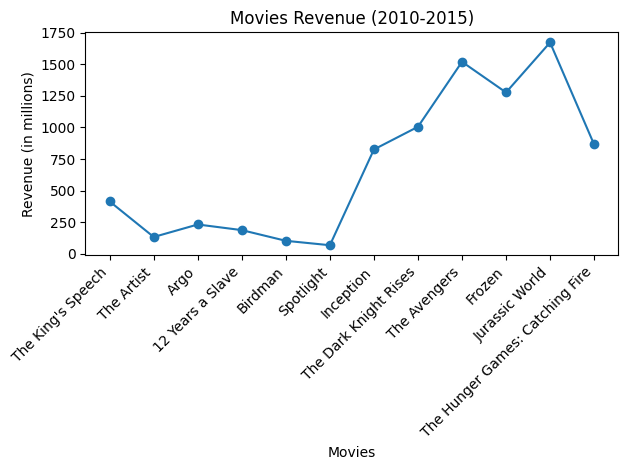

In [9]:
movies = oscar_movies + non_oscar_movies
revenues = oscar_revenue + non_oscar_revenue

plt.plot(movies, revenues, marker='o')
plt.title("Movies Revenue (2010-2015)")
plt.xlabel('Movies')
plt.ylabel('Revenue (in millions)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

### 2.4 Saving a figure — `plt.savefig()`

**Definition.** `plt.savefig()` writes the current figure to disk instead of (or as well as) showing
it. Format is inferred from the extension: `.png`, `.jpg`, `.svg`, `.pdf`.

**Usage**

```python
plt.savefig('movies_revenue.png', dpi=300, bbox_inches='tight')
```

**Actions / arguments**
- `dpi=300` — dots per inch; 300 is print quality, the default 100 is fine for screen.
- `bbox_inches='tight'` — crop away surrounding whitespace and keep rotated labels inside the image.
- `transparent=True` — optional, drop the white background (useful for slides).

**Important gotcha:** `plt.show()` renders **and clears** the figure, so `savefig()` afterwards
writes an *empty* canvas. Note this cell's own output — `<Figure size 640x480 with 0 Axes>` — the
figure was already flushed at the cell boundary. **Always call `savefig()` before `show()`, in the
same cell as the plotting code.**


In [10]:
plt.savefig('movies_revenue.png', dpi=300, bbox_inches='tight')  # Save the figure as a PNG file

<Figure size 640x480 with 0 Axes>

---
## 3. Bar Chart

**Definition.** A bar chart encodes values as the **length of rectangles**. Because length is read
far more accurately than position-on-a-line, bars are the right choice for comparing **discrete
categories** — and unlike a line chart they make no claim that the categories are ordered.

**Usage**

```python
plt.bar(x, height)      # vertical bars
plt.barh(y, width)      # horizontal bars — better for long category names
```

**Key parameters:** `color`, `width` (default `0.8`), `label`, `edgecolor`, `alpha` (transparency),
`bottom` (for stacking).

**Line vs bar:** use a **line** for a trend over time, a **bar** for comparing magnitudes.


### 3.1 A basic bar chart with value labels and axis limits

**Definition.** `plt.text()` draws arbitrary text at data coordinates — the standard way to print
each bar's exact value on top of it. `plt.xlim()` / `plt.ylim()` set the visible range of each axis.

**Usage**

```python
plt.text(x, y, s, ha='center', va='bottom')   # s = the string to draw
plt.ylim(bottom, top)
```

**Actions in the cell below**
- `plt.bar(years, oscar_revenue, color='purple', label='Oscar Winners')` — draw the bars.
- The `for` loop calls `plt.text()` once per bar, at `oscar_revenue[i] + 3` so the label floats just
  above the bar instead of overlapping it.
- `ha='center'` / `va='bottom'` — horizontal/vertical alignment of the text relative to that point.
- `plt.ylim(0, max(...) + 50)` — **start the y-axis at 0**; a truncated baseline exaggerates
  differences in bar length and is the classic misleading chart.
- `plt.xlim(2009, 2016)` — a little padding so the first and last bars aren't flush against the
  frame.


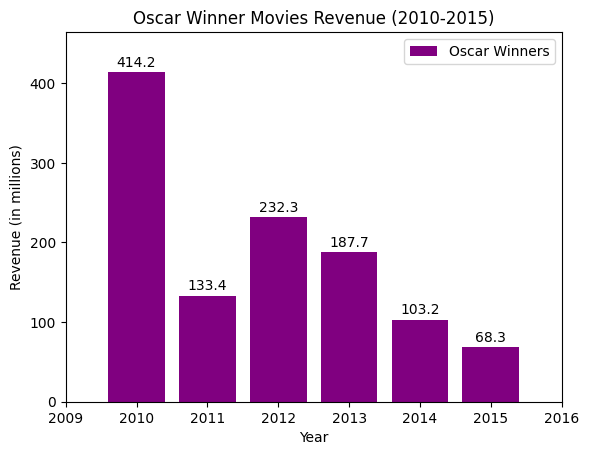

In [11]:
# Real data

# Oscar winner movies from 2010 to 2020
oscar_movies = [
    "The King's Speech",
    "The Artist",
    "Argo",
    "12 Years a Slave",
    "Birdman",
    "Spotlight"
]
years = [2010, 2011, 2012, 2013, 2014, 2015]
oscar_revenue = [414.2, 133.4, 232.3, 187.7, 103.2, 68.3]  # in millions

plt.bar(years, oscar_revenue, color='purple', label='Oscar Winners')
plt.xlabel('Year')
plt.ylabel('Revenue (in millions)')
plt.title('Oscar Winner Movies Revenue (2010-2015)')
plt.legend()
for i in range(len(years)):
    plt.text(years[i], oscar_revenue[i]+3, oscar_revenue[i], va='bottom', ha='center')
# plt.text(years[0], oscar_revenue[0]+3, oscar_revenue[0], va='bottom', ha='center')
plt.ylim(0, max(oscar_revenue) + 50)
plt.xlim(2009, 2016)
plt.show()

### 3.2 The same chart, re-run

This cell is an exact repeat of the previous one — a scratch re-run kept for reference. Because
`plt.show()` in the previous cell cleared the figure, re-executing produces an identical, fully
independent chart. Handy to remember: **each cell that ends in `plt.show()` starts from a clean
canvas.**


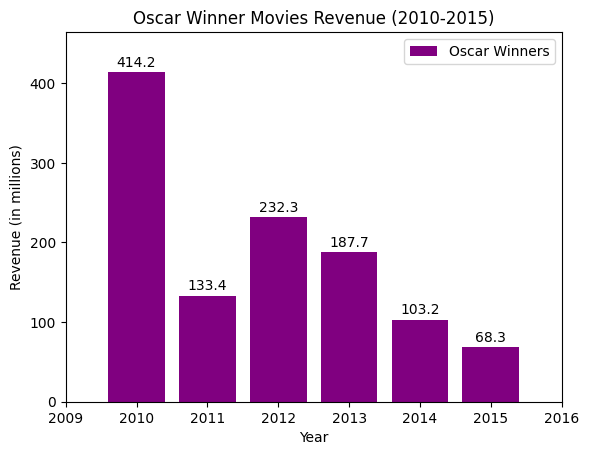

In [12]:
# Real data

# Oscar winner movies from 2010 to 2020
oscar_movies = [
    "The King's Speech",
    "The Artist",
    "Argo",
    "12 Years a Slave",
    "Birdman",
    "Spotlight"
]
years = [2010, 2011, 2012, 2013, 2014, 2015]
oscar_revenue = [414.2, 133.4, 232.3, 187.7, 103.2, 68.3]  # in millions

plt.bar(years, oscar_revenue, color='purple', label='Oscar Winners')
plt.xlabel('Year')
plt.ylabel('Revenue (in millions)')
plt.title('Oscar Winner Movies Revenue (2010-2015)')
plt.legend()
for i in range(len(years)):
    plt.text(years[i], oscar_revenue[i]+3, oscar_revenue[i], va='bottom', ha='center')
# plt.text(years[0], oscar_revenue[0]+3, oscar_revenue[0], va='bottom', ha='center')
plt.ylim(0, max(oscar_revenue) + 50)
plt.xlim(2009, 2016)
plt.show()

### 3.3 Overlapping bars — the problem

**Definition.** Calling `plt.bar()` twice with the **same x positions** draws the second set of bars
*on top of* the first. This is neither a grouped chart nor a stacked one — the shorter series simply
hides in front of the taller one.

**Actions in the cell below**
- Orange (non-Oscar, tall) is drawn first, purple (Oscar, short) second — so purple sits in front
  and is readable *only because* it happens to be smaller. Reverse the order and it vanishes.
- Nothing here communicates that the two totals should be added or compared side by side.

**The two correct fixes**
1. **Grouped bars** — offset the x positions so bars sit next to each other → section 3.4.
2. **Stacked bars** — `plt.bar(x, series2, bottom=series1)`, when the parts genuinely sum to a
   meaningful total.


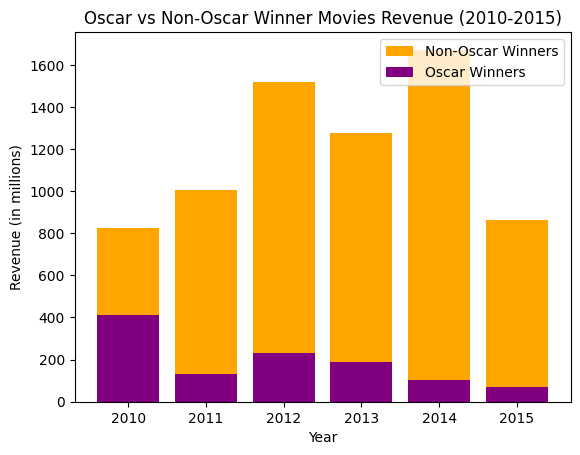

In [13]:
non_oscar_movies = [
    "Inception",
    "The Dark Knight Rises",
    "The Avengers",
    "Frozen",
    "Jurassic World",
    "The Hunger Games: Catching Fire"
]
non_oscar_revenue = [825.5, 1004.9, 1518.8, 1276.5, 1671.7, 865.0]  # in millions

plt.bar(years, non_oscar_revenue, color='orange', label='Non-Oscar Winners')
plt.bar(years, oscar_revenue, color='purple', label='Oscar Winners')
plt.xlabel('Year')
plt.ylabel('Revenue (in millions)')
plt.title("Oscar vs Non-Oscar Winner Movies Revenue (2010-2015)")
plt.legend()
plt.show()

### 3.4 Grouped bar chart — offsetting with `np.arange`

**Definition.** A grouped ("clustered") bar chart places one bar per series side by side within each
category. Matplotlib has no built-in grouping, so you shift the x positions yourself: replace the
real x values with evenly-spaced integers, then add/subtract a fraction of the bar width.

**Usage**

```python
import numpy as np
x = np.arange(len(years))     # 0, 1, 2, ... one slot per category
width = 0.4
plt.bar(x - width/2, series1, width, label='A')
plt.bar(x + width/2, series2, width, label='B')
plt.xticks(x, years)          # put the real labels back on the integer slots
```

**Actions in the cell below**
- `np.arange(len(years))` — integer slot positions; needed because arithmetic like `x - width/2`
  must apply element-wise, which works on a NumPy array but not on a plain Python list.
- `width = 0.4` — two bars of 0.4 fill 0.8 of each unit slot, leaving a 0.2 gap between groups.
- `x - width/2` / `x + width/2` — shift left and right of the slot centre.
- `plt.xticks(x, years)` — **essential**; without it the axis shows 0–5 instead of 2010–2015.

**Rule of thumb:** `n_bars * width ≤ 0.8`, so the groups stay visually separated.


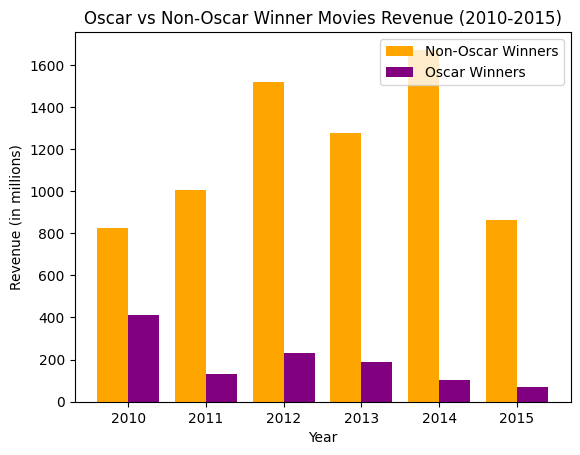

In [14]:
import numpy as np
width = 0.4
x = np.arange(len(years))  # the label locations

plt.bar(x - width/2, non_oscar_revenue, width, color='orange', label='Non-Oscar Winners')
plt.bar(x + width/2, oscar_revenue, width, color='purple', label='Oscar Winners')
plt.xlabel('Year')
plt.ylabel('Revenue (in millions)')
plt.title("Oscar vs Non-Oscar Winner Movies Revenue (2010-2015)")
plt.xticks(x, years)
plt.legend()
plt.show()

#### `np.arange()` — the helper behind the offsets

**Definition.** `np.arange(n)` returns a NumPy array of evenly spaced values `[0, 1, ..., n-1]` —
like `range()`, but as an array that supports vectorised arithmetic.

**Usage**

```python
np.arange(5)          # array([0, 1, 2, 3, 4])
np.arange(5) - 0.2    # array([-0.2, 0.8, 1.8, 2.8, 3.8])  <- element-wise, the key property
list(range(5)) - 0.2  # TypeError
```

That element-wise subtraction is exactly what shifts a whole series of bars at once.


In [15]:
np.arange(5)

array([0, 1, 2, 3, 4])

### 3.5 Three bars per group

**Definition.** The same offset pattern generalised to *n* series: with three bars use offsets
`-width, 0, +width` and a smaller `width` so each group still fits in its slot.

**Usage**

```python
width = 0.25                    # 3 * 0.25 = 0.75 <= 0.8, groups stay separated
plt.bar(x - width, s1, width)
plt.bar(x,         s2, width)
plt.bar(x + width, s3, width)
```

**Actions in the cell below**
- `width` drops from `0.4` to `0.25` to make room for the third bar.
- Offsets `-width`, `0`, `+width` centre the middle bar on the tick.
- The third series here repeats `non_oscar_revenue` purely to demonstrate the spacing — note the
  duplicated `label='Non-Oscar Winners'`, which makes the legend show the same entry twice. With a
  genuine third series, give it its own label and colour.

**Beyond three or four series** grouped bars get cramped — switch to a stacked bar chart, small
multiples (`plt.subplots()`), or a line chart.


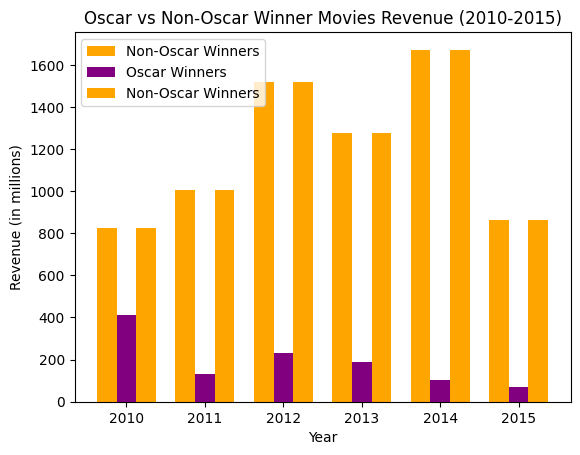

In [16]:
import numpy as np
width = 0.25
x = np.arange(len(years))  # the label locations

plt.bar(x - width, non_oscar_revenue, width, color='orange', label='Non-Oscar Winners')
plt.bar(x, oscar_revenue, width, color='purple', label='Oscar Winners')
plt.bar(x + width, non_oscar_revenue, width, color='orange', label='Non-Oscar Winners')

plt.xlabel('Year')
plt.ylabel('Revenue (in millions)')
plt.title("Oscar vs Non-Oscar Winner Movies Revenue (2010-2015)")
plt.xticks(x, years)
plt.legend()
plt.show()

---
## 4. Scatter Plot

**Definition.** A scatter plot draws one **independent marker per observation** at its `(x, y)`
position, with nothing connecting them. It is the chart for showing the **relationship between two
numeric variables** across many individuals — whether they rise together, fall together, or are
unrelated.

**Usage**

```python
plt.scatter(x, y, s=..., c=..., cmap=..., alpha=..., marker=...)
```

| Parameter | Meaning |
| --- | --- |
| `s` | marker **size** in points² — a scalar, or one value per point |
| `color` | one fixed colour, or an explicit list of colour names |
| `c` | numeric values mapped to colours **through a colormap** |
| `cmap` | the colormap `c` is read through (`'OrRd'`, `'plasma'`, `'viridis'`) |
| `alpha` | 0–1 transparency, so overlapping markers stay readable |
| `marker` | marker shape: `'o'` `'s'` `'^'` `'<'` `'*'` `'D'` `'x'` |

Because `s` and `c` accept **one value per point**, a scatter plot can encode up to four variables
at once: x, y, size and colour.

**Important:** `color=` and `c=` are mutually exclusive. Passing both raises
`ValueError: Supply a 'c' argument or a 'color' kwarg but not both`. Use `color=` for colours you
have chosen yourself, `c=` + `cmap=` to map a number to a colour. The next two cells show each.

**Line vs bar vs scatter:** line = trend over an ordered axis; bar = magnitudes across categories;
scatter = correlation between two measured quantities.

**The data:** ten people, their `ages` and their `blood_pressure` — the question being whether blood
pressure rises with age.


### 4.1 Explicit colours — a threshold rule with `color=`

**Definition.** When the colour should encode a **category or a rule** rather than a continuous
value, build the colour list yourself and pass it as `color=`.

**Usage**

```python
colors = ["green" if bp < 130 else "red" for bp in blood_pressure]
plt.scatter(x, y, color=colors)
```

**Actions in the cell below**
- The list comprehension turns each reading into a colour: **green** below 130, **red** at or above
  it — the conventional threshold for high blood pressure. One colour per point, in the same order
  as the data.
- `s=100` — a single scalar, so every marker is the same size (size encodes nothing here).
- `alpha=0.7` — slight transparency; overlapping markers stay distinguishable.
- `marker='<'` — left-pointing triangles instead of the default circles.
- `plt.grid()` — reference lines to read values off the plane.
- The commented-out `colors` list above is the alternative "one arbitrary colour per person", which
  encodes nothing — the threshold rule is the meaningful version.

**Note:** colours applied this way get **no legend and no colorbar** — Matplotlib doesn't know what
green and red mean. Add a caption, or plot the two groups as two labelled `scatter` calls.


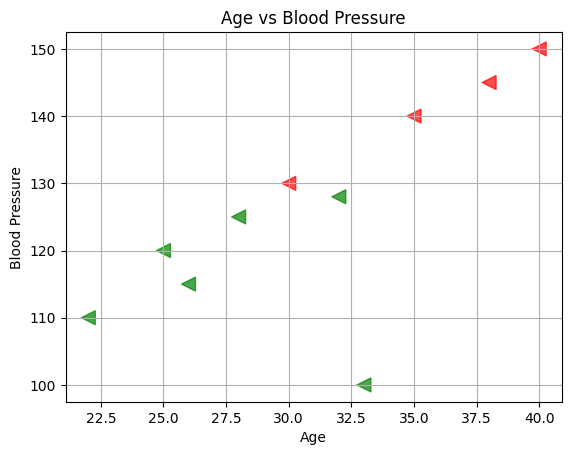

In [17]:
# Scatter Plot
people = ['Alice', 'Bob', 'Charlie', 'David', 'Eva','Rachel', 'John', 'Mike', 'Sarah', 'Tom']
ages = [25, 30, 35, 40, 22, 28, 33, 38, 26, 32]
blood_pressure = [120, 130, 140, 150, 110, 125, 100, 145, 115, 128]
# colors = ['red', 'blue', 'green', 'orange', 'purple', 'brown', 'pink', 'gray', 'cyan', 'magenta']

colors = ["green" if bp < 130 else "red" for bp in blood_pressure]

plt.scatter(ages, blood_pressure, color=colors, s=100, alpha=0.7, marker='<')
plt.xlabel('Age')
plt.ylabel('Blood Pressure')
plt.title('Age vs Blood Pressure')
plt.grid()

### 4.2 Continuous colour — `c=` + `cmap=` + `plt.colorbar()`

**Definition.** Passing **numbers** to `c=` makes Matplotlib map them onto a *colormap*: the lowest
value gets one end of the gradient, the highest the other. `plt.colorbar()` then draws the legend
for that gradient — the scale that says which colour means which number.

**Usage**

```python
plt.scatter(x, y, c=values, cmap='OrRd', s=values)
plt.colorbar(label='Blood Pressure')
```

**Actions in the cell below**
- `c=blood_pressure` — colour now varies **continuously** with the reading, so the ordering is
  visible (no hard 130 cut-off).
- `cmap='OrRd'` — a *sequential* colormap, pale orange → deep red. Sequential maps suit values that
  run low→high; use a *diverging* map (`'coolwarm'`) only when there is a meaningful midpoint.
- `s=blood_pressure` — **size also** encodes the reading. Passing the raw values means the area is
  in points², so 100 vs 150 is a subtle difference; scale for contrast, e.g. `s=(bp - 90) * 8`.
- `plt.colorbar(label='Blood Pressure')` — the colour key. Without it the gradient is unreadable.
- `colors` is still computed on the line above but **no longer used** — it is left over from 4.1.

**Design note:** colour and size here encode the *same* variable (blood pressure), which is
redundant. That is fine as emphasis, but the real power of `s` is a **third** variable — e.g.
`c=blood_pressure, s=weight`.


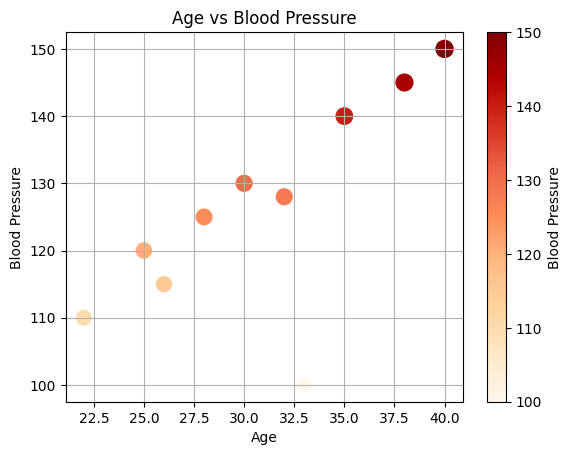

In [18]:
# Scatter Plot
people = ['Alice', 'Bob', 'Charlie', 'David', 'Eva','Rachel', 'John', 'Mike', 'Sarah', 'Tom']
ages = [25, 30, 35, 40, 22, 28, 33, 38, 26, 32]
blood_pressure = [120, 130, 140, 150, 110, 125, 100, 145, 115, 128]
# colors = ['red', 'blue', 'green', 'orange', 'purple', 'brown', 'pink', 'gray', 'cyan', 'magenta']

colors = ["green" if bp < 130 else "red" for bp in blood_pressure]

plt.scatter(ages, blood_pressure,  s=blood_pressure, cmap='OrRd', c=blood_pressure)
plt.xlabel('Age')
plt.ylabel('Blood Pressure')
plt.title('Age vs Blood Pressure')
plt.grid()
plt.colorbar(label='Blood Pressure')  # Add a colorbar to indicate the blood pressure values

### 4.3 Annotations — labelling individual points with `plt.annotate()`

**Definition.** `plt.annotate()` attaches text to a specific data point. In a scatter plot each
marker is one individual, so annotations are what turn anonymous dots into named observations —
here, which person each reading belongs to.

**Usage**

```python
plt.annotate(text, xy=(x, y), xytext=(x+0.5, y+0.5), fontsize=8)

# with a connecting arrow:
plt.annotate(text, xy=(x, y), xytext=(x+2, y+10),
             arrowprops=dict(arrowstyle='->', color='gray'))
```

| Argument | Meaning |
| --- | --- |
| `text` | the string to draw |
| `xy` | the point being annotated |
| `xytext` | where the text itself sits (defaults to `xy`) |
| `arrowprops` | if given, draws an arrow from the text back to `xy` |

**`annotate` vs `text`:** `plt.text()` (used on the bar chart in 3.1) just places a string at a
position. `plt.annotate()` knows about the *point* it refers to, so it can offset the label and draw
an arrow back to it.

**Actions in the cell below**
- The `for` loop annotates every point, `people[i]` at that person's `(age, blood_pressure)`.
- `xytext=(ages[i]+0.5, blood_pressure[i]+0.5)` — nudge the label up and to the right so it doesn't
  sit on top of its own marker. No `arrowprops`, so it's plain offset text.
- `fontsize=8`, `alpha=0.7` — keep ten labels from overwhelming ten points.
- `plt.xlim(...)` / `plt.ylim(...)` — extend the top and right so labels near the edge aren't
  clipped.

**Two things to watch**
1. The limits start at exactly `min(ages)` and `min(blood_pressure)`, so the lowest-left points sit
   *on* the frame and their labels run off it. Pad both ends: `plt.xlim(min(ages)-2, max(ages)+5)`.
2. Annotating every point only works for small datasets. Beyond ~20 points labels collide — annotate
   just the outliers.


(100.0, 155.0)

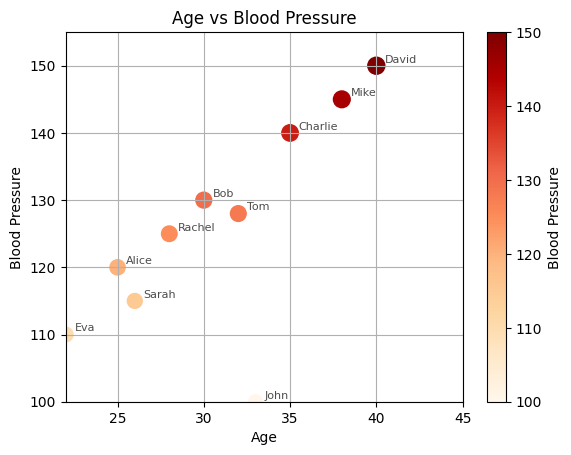

In [19]:
#Annotations
# Scatter Plot
people = ['Alice', 'Bob', 'Charlie', 'David', 'Eva','Rachel', 'John', 'Mike', 'Sarah', 'Tom']
ages = [25, 30, 35, 40, 22, 28, 33, 38, 26, 32]
blood_pressure = [120, 130, 140, 150, 110, 125, 100, 145, 115, 128]
# colors = ['red', 'blue', 'green', 'orange', 'purple', 'brown', 'pink', 'gray', 'cyan', 'magenta']

colors = ["green" if bp < 130 else "red" for bp in blood_pressure]

plt.scatter(ages, blood_pressure,  s=blood_pressure, cmap='OrRd', c=blood_pressure)
plt.xlabel('Age')
plt.ylabel('Blood Pressure')
plt.title('Age vs Blood Pressure')
plt.grid()
plt.colorbar(label='Blood Pressure')  # Add a colorbar to indicate the blood pressure values

for i in range(len(people)):
    plt.annotate(people[i], xy=(ages[i], blood_pressure[i]),  xytext=(ages[i]+0.5, blood_pressure[i]+0.5), fontsize=8, color='black', alpha=0.7)
plt.xlim(min(ages), max(ages)+5)
plt.ylim(min(blood_pressure), max(blood_pressure)+5)

### 4.4 Two series on one scatter — grouping by category

**Definition.** Calling `plt.scatter()` twice before `plt.show()` overlays two groups on the same
axes, each with its own colour and label. This is the standard way to show a **categorical split**
in a scatter plot — and, unlike 4.1's colour rule, it produces a real legend.

**Usage**

```python
plt.scatter(x1, y1, color='blue',   label='Winter', s=100)
plt.scatter(x2, y2, color='orange', label='Summer', s=100)
plt.legend()
```

**Actions in the cell below**
- Two measurements — temperature and humidity — for five cities, in two seasons.
- Winter in blue, summer in orange; `s=100` keeps both series the same marker size, so **colour is
  the only encoding** and it maps cleanly to the legend.
- `label=` on each call **+** `plt.legend()` — the same pairing as the multi-line chart in 1.2.
- The two clusters separate along the x-axis (winter cold / summer hot) and the downward drift
  within each shows humidity falling as temperature rises.

**Naming note:** the cell is titled "Multiple Plots", but this is **multiple series on one set of
axes** — one figure, one coordinate system. Genuinely separate panels are a different tool:

```python
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.scatter(winter_temps, winter_humidity, color='blue')
ax2.scatter(summer_temps, summer_humidity, color='orange')
```

Use **one axes** when the series share a scale and should be compared directly; use **subplots**
when they don't, or when overlap makes a single panel unreadable.


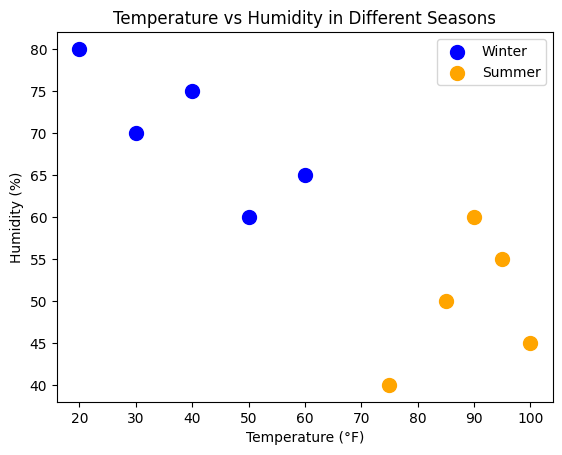

In [20]:
# Multiple Plots
cities = ['New York', 'Los Angeles', 'Chicago', 'Houston', 'Phoenix']

# winter: Temperature and Humidity
winter_temps = [30, 50, 20, 40, 60]
winter_humidity = [70, 60, 80, 75, 65]

# summer: Temperature and Humidity
summer_temps = [85, 75, 90, 95, 100]
summer_humidity = [50, 40, 60, 55, 45]

plt.scatter(winter_temps, winter_humidity, color='blue', label='Winter', s=100)
plt.scatter(summer_temps, summer_humidity, color='orange', label='Summer', s=100)
plt.xlabel('Temperature (°F)')
plt.ylabel('Humidity (%)')
plt.title('Temperature vs Humidity in Different Seasons')
plt.legend()


---
## 5. Histogram

**Definition.** A histogram shows the **distribution of a single numeric variable**. It slices the
value range into intervals called **bins** and draws a bar whose height is the *count* of
observations falling in that bin.

**Bar chart vs histogram** — they look alike but answer different questions:

| | Bar chart | Histogram |
| --- | --- | --- |
| x-axis | discrete **categories** | a **continuous numeric range** cut into bins |
| Bar height | a value you supply | a count Matplotlib computes |
| Input | `x` **and** `height` | one list of raw values |
| Gaps between bars | yes — categories are separate | no — the bins are adjacent |
| Question | "which category is biggest?" | "how are the values spread out?" |

**Usage**

```python
plt.hist(data, bins=10, color=..., edgecolor='black')
```

| Parameter | Meaning |
| --- | --- |
| `bins` | number of equal-width bins, **or** a list of explicit bin edges |
| `edgecolor` | outline colour — without it adjacent bars merge into one block |
| `range` | `(lo, hi)` limit of the values considered |
| `density` | `True` → area sums to 1 (a probability density instead of counts) |
| `cumulative` | `True` → each bar adds the ones before it |
| `histtype` | `'bar'` (default), `'step'`, `'stepfilled'` |
| `log` | `True` → log-scaled y-axis, for very skewed data |

**Return value:** `plt.hist()` returns `(counts, bin_edges, patches)` — useful when you want the
numbers as well as the picture.

**Choosing `bins` is the whole game.** Too few hides the shape; too many turns it into noise. Try
several before trusting what you see.

**The data:** the ages of 250 patients, generated around a mean of 45 — the question being what the
age profile of the clinic looks like.


### 5.1 A basic histogram — equal-width bins

**Definition.** Passing an **integer** to `bins` splits the range `min(data) → max(data)` into that
many equal-width intervals and counts the values in each.

**Usage**

```python
plt.hist(data, bins=10, edgecolor='black')
```

**Actions in the cell below**
- `np.random.normal(loc=45, scale=15, size=250)` — 250 ages drawn around a mean of 45 with a spread
  (standard deviation) of 15. `np.random.seed(42)` fixes the generator so the chart is identical on
  every re-run — always seed when a notebook's output should be reproducible.
- The boolean mask `(patient_ages > 0) & (patient_ages < 100)` filters out impossible ages the
  normal distribution can produce at the tails.
- `bins=10` — ten equal-width intervals across the age range.
- `edgecolor='black'` — **do this always**; without outlines neighbouring bars fuse into one shape
  and the bin structure disappears.
- `plt.grid(axis='y', alpha=0.3)` — faint horizontal lines, so counts can be read off.

**Reading it:** the bars are tallest in the middle and taper off both ways — the symmetric bell that
`np.random.normal` produces. A histogram makes shape visible: symmetric, skewed, or two-peaked.


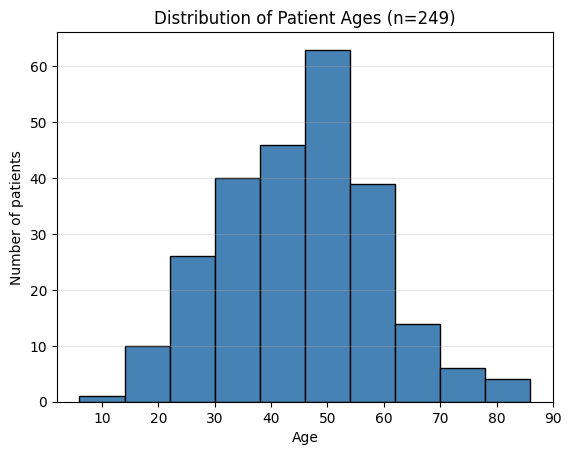

In [23]:
# Histogram
import numpy as np

np.random.seed(42)  # fixed seed -> the same "random" data every run
patient_ages = np.random.normal(loc=45, scale=15, size=250).round().astype(int)
patient_ages = patient_ages[(patient_ages > 0) & (patient_ages < 100)]  # drop impossible ages

plt.hist(patient_ages, bins=10, color='steelblue', edgecolor='black')
plt.xlabel('Age')
plt.ylabel('Number of patients')
plt.title('Distribution of Patient Ages (n=%d)' % len(patient_ages))
plt.grid(axis='y', alpha=0.3)
plt.show()


### 5.2 Explicit bin edges, a reference line, and the returned counts

**Definition.** Passing a **list** to `bins` sets the edges yourself, so the intervals can be
unequal and line up with categories that mean something in the domain (child / young adult /
middle-aged / senior) rather than arbitrary equal slices.

**Usage**

```python
bins = [0, 18, 30, 45, 60, 75, 100]
counts, edges, patches = plt.hist(data, bins=bins, edgecolor='black')
plt.axvline(data.mean(), color='red', linestyle='--', label='Mean')
```

**Actions in the cell below**
- `bins = [0, 18, 30, 45, 60, 75, 100]` — six brackets from seven edges. Each bin includes its left
  edge and excludes its right (`[0, 18)`, `[18, 30)`, …); only the **last** bin includes both ends.
- `plt.axvline(...)` — a **vertical** reference line at the mean. `axhline()` is the horizontal
  twin, useful for marking a target or threshold.
- `linestyle='--'` + `label=` + `plt.legend()` — mark the line as an annotation, not another series.
- `plt.xticks(bins)` — put a tick at every bin edge, so the brackets are readable.
- Unpacking `counts, edges, patches` gives the numbers behind the chart; `print()` shows the exact
  count in each bracket.

**Caution with unequal bins:** bar **height** is a raw count, so a wide bin naturally collects more
observations and looks more important than a narrow one. When bin widths differ and you want honest
comparison, use `density=True` — height then becomes count ÷ width, making **area** the quantity
that is comparable.


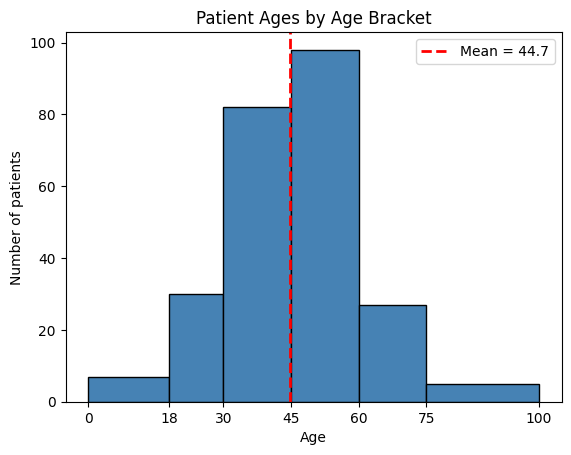

counts per bin: [ 7. 30. 82. 98. 27.  5.]
bin edges     : [  0.  18.  30.  45.  60.  75. 100.]


In [24]:
# Custom bin edges + a reference line
bins = [0, 18, 30, 45, 60, 75, 100]  # meaningful age brackets, deliberately unequal

counts, edges, patches = plt.hist(patient_ages, bins=bins,
                                  color='steelblue', edgecolor='black')

plt.axvline(patient_ages.mean(), color='red', linestyle='--', linewidth=2,
            label='Mean = %.1f' % patient_ages.mean())

plt.xlabel('Age')
plt.ylabel('Number of patients')
plt.title('Patient Ages by Age Bracket')
plt.xticks(bins)
plt.legend()
plt.show()

print('counts per bin:', counts)
print('bin edges     :', edges)


---
## 6. Pie Chart

**Definition.** A pie chart divides a circle into wedges whose **angles are proportional to their
values**. It shows **parts of a single whole** — the composition of one total, not a comparison
between separate quantities.

**Usage**

```python
plt.pie(values, labels=names, autopct='%1.1f%%')
```

| Parameter | Meaning |
| --- | --- |
| `labels` | text drawn beside each wedge |
| `autopct` | format string for the percentage inside each wedge, e.g. `'%1.1f%%'` |
| `colors` | list of wedge colours |
| `explode` | per-wedge offset from the centre, as a fraction of the radius |
| `startangle` | rotation of the first wedge, in degrees counter-clockwise from the x-axis |
| `shadow` | drop shadow under the wedges |
| `wedgeprops` | dict of wedge styling — `edgecolor`, `linewidth`, `linestyle`, `alpha` |
| `counterclock` | `False` to lay wedges out clockwise |

**Percentages are automatic:** unlike every other chart here, `plt.pie()` normalises for you — it
divides each value by the total, so raw amounts can be passed straight in. (If the values already
sum to 1 or less, it draws a partial pie instead.)

**Use a pie only when** the parts genuinely sum to a meaningful whole, and there are **≤ 5–6 slices**
that differ clearly in size. Humans compare angles poorly — for close values, or for ranking, a bar
chart is strictly more readable. There is no such thing as a fair pie chart with 12 similar slices.

**The data:** a monthly budget — five expense categories that add up to one month's spending, which
is exactly the "parts of a whole" case a pie is for.


### 6.1 The minimal pie chart

**Definition.** With just values and `labels`, `plt.pie()` draws the wedges and names them. Nothing
else is required — the angles are computed from the values.

**Usage**

```python
plt.pie(amounts, labels=expenses)
```

**Actions in the cell below**
- `plt.pie(amounts, labels=expenses)` — five wedges, sized by amount, each labelled.
- `plt.title(...)` — describe the whole.
- `plt.style.use('dark_background')` — switch to the dark theme; `plt.style.available` (commented
  out) lists every installed style.

**Two things to note**
1. **No `autopct`** — the reader gets relative sizes by eye but no numbers. Add
   `autopct='%1.1f%%'` (next cell) whenever the exact share matters.
2. **`plt.style.use()` is global and applies from the *next* figure onward.** Placed after the plot
   it barely affects this chart, but it darkens **every cell run afterwards**, including the
   histograms above if you re-run them. Reset with `plt.style.use('default')` when you're done.

Since Matplotlib 3.x a pie is drawn with an equal aspect ratio automatically, so the old
`plt.axis('equal')` incantation is no longer needed to keep the circle round.


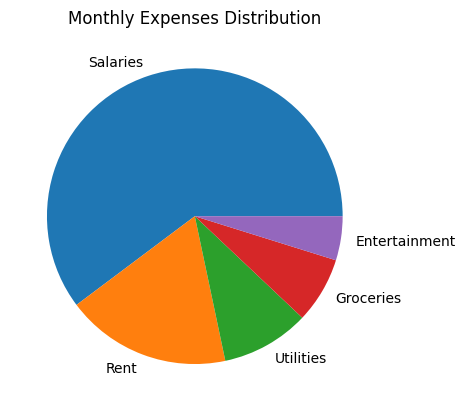

In [22]:
# Pie Chart
expenses = ["Salaries", "Rent", "Utilities", "Groceries", "Entertainment"]
amounts = [5000, 1500, 800, 600, 400]

plt.pie(amounts, labels=expenses)
plt.title('Monthly Expenses Distribution')
plt.style.use('dark_background')
# plt.style.available

### 6.2 A styled pie — percentages, colours, exploded wedges, shadow

**Definition.** The same pie with the presentation parameters filled in: printed percentages,
a chosen palette, wedge outlines, and slices pulled out of the circle for emphasis.

**Usage**

```python
explode = (0, 0.4, 0, 0, 0.2)          # one entry per wedge, in data order
plt.pie(amounts, labels=expenses, autopct='%1.1f%%', colors=clors,
        wedgeprops={'edgecolor': 'black', 'linewidth': 1},
        explode=explode, shadow=True)
```

**Actions in the cell below**
- `autopct='%1.1f%%'` — print each share inside its wedge. It's an old-style Python format:
  `%1.1f` = one decimal place, and the doubled `%%` is a literal percent sign. `'%d%%'` gives whole
  numbers.
- `colors=clors` — an explicit hex palette, one colour per wedge, in the same order as the data.
- `wedgeprops={'edgecolor': 'black', 'linewidth': 1}` — a dict of styling passed through to each
  wedge; the separating outline is what stops adjacent pastel colours from blending. The commented
  keys (`linestyle`, `fill`, `alpha`) are other options the same dict accepts.
- `explode=(0, 0.4, 0, 0, 0.2)` — **one value per wedge**, each the distance to push that slice out
  as a fraction of the radius. Here `0.4` pulls **Rent** (index 1) well out and `0.2` nudges
  **Entertainment** (index 4). *The inline comment says "the first slice", but index 0 — Salaries —
  is the one left in place.* Keep offsets small (≤ 0.1) unless you really mean to shout.
- `shadow=True` — a drop shadow. Decorative; it adds no information and slightly distorts the
  wedge edges, so most style guides leave it off.
- `plt.show()` — render (this cell has it, 6.1 didn't).

**Emphasis costs accuracy:** exploding and shadowing make a slice *look* bigger than its angle
warrants. Use `explode` on at most one wedge, to point at a conclusion you state in words anyway.


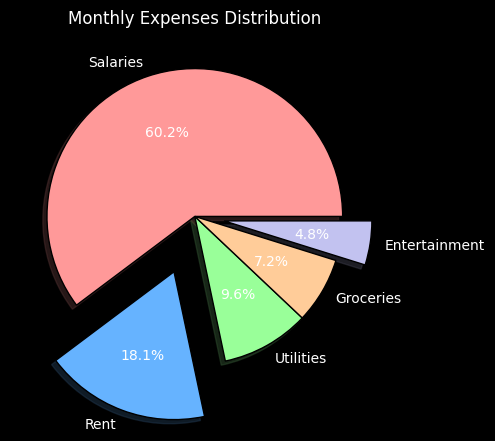

In [23]:
# Pie Chart
expenses = ["Salaries", "Rent", "Utilities", "Groceries", "Entertainment"]
amounts = [5000, 1500, 800, 600, 400]
clors = ['#ff9999','#66b3ff','#99ff99','#ffcc99','#c2c2f0']
explode = (0, 0.4, 0, 0, 0.2)  # explode the first slice

plt.pie(amounts, labels=expenses, autopct='%1.1f%%', colors=clors,
        wedgeprops={'edgecolor': 'black', 'linewidth': 1,
        # 'linestyle': '--',
        # 'fill': False
        # 'alpha': 0.1,
        },
        explode=explode,
        shadow=True,
        )
plt.title('Monthly Expenses Distribution')
# plt.style.use('classic')
# plt.style.available
plt.show()

### 6.3 Rotating the pie — `startangle`

**Definition.** `startangle` rotates the whole pie by *n* degrees counter-clockwise from the
positive x-axis (3 o'clock). It changes **where** the first wedge begins, never the proportions.

**Usage**

```python
plt.pie(amounts, labels=expenses, startangle=180)
plt.pie(amounts, labels=expenses, startangle=90, counterclock=False)  # start at 12 o'clock, clockwise
```

**Actions in the cell below**
- `startangle=180` — the first wedge (Salaries) now starts at 9 o'clock instead of 3 o'clock, and
  the whole chart rotates with it.
- `shadow=True` has been **dropped** here — compare with 6.2 to see how much cleaner the wedge
  edges read without it.
- Everything else — `autopct`, `colors`, `wedgeprops`, `explode` — is unchanged from 6.2.

**Why rotate at all?** Two practical reasons: `startangle=90` with `counterclock=False` starts the
largest slice at 12 o'clock and runs clockwise, which is how people naturally read a pie; and
rotating can move a crowded cluster of small-slice labels away from where they overlap.

**Convention:** sort the data largest → smallest before plotting, then start at 90°. The reader
gets a consistent, scannable order instead of an arbitrary one.


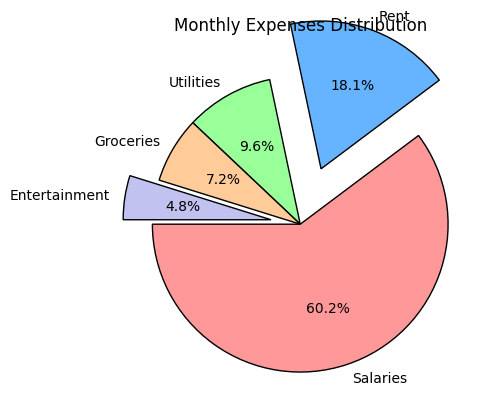

In [25]:
# Pie Chart
expenses = ["Salaries", "Rent", "Utilities", "Groceries", "Entertainment"]
amounts = [5000, 1500, 800, 600, 400]
clors = ['#ff9999','#66b3ff','#99ff99','#ffcc99','#c2c2f0']
explode = (0, 0.4, 0, 0, 0.2)  # explode the first slice,


plt.pie(amounts, labels=expenses, autopct='%1.1f%%', colors=clors,
        wedgeprops={'edgecolor': 'black', 'linewidth': 1,
        # 'linestyle': '--',
        # 'fill': False
        # 'alpha': 0.1,
        },
        explode=explode,
        startangle=180
        )
plt.title('Monthly Expenses Distribution')
# plt.style.use('classic')
# plt.style.available
plt.show()

---
## 7. Box Plot

**Definition.** A box plot (or box-and-whisker plot) is a **statistical** visualization that
summarises the distribution of a dataset using **five key numbers**:

| # | Number | Meaning |
| --- | --- | --- |
| 1 | **Minimum** | lowest value that is *not* an outlier |
| 2 | **Q1** — first quartile | 25th percentile — 25% of the data is below it |
| 3 | **Q2** — median | 50th percentile — the middle value |
| 4 | **Q3** — third quartile | 75th percentile — 75% of the data is below it |
| 5 | **Maximum** | highest value that is *not* an outlier |

Unlike a histogram — which draws the *whole* shape — a box plot compresses a distribution into
those five numbers. That compression is the point: several box plots sit side by side and stay
readable, which is what makes them the tool for **comparing distributions across groups**.

### Worked example

```
data = [7, 8, 5, 6, 9, 4, 10, 12, 15]
```

**Step 1 — sort the data.** Every quartile is positional, so nothing can be computed until the
values are in order:

```
4, 5, 6, 7, 8, 9, 10, 12, 15        (n = 9)
```

**Step 2 — Q2, the median.** With `n = 9` (odd) the middle value is the 5th:

```
4, 5, 6, 7, [8], 9, 10, 12, 15   ->  Q2 = 8
```

(With an *even* count there is no single middle value, so the median is the average of the middle
two.)

**Step 3 — Q1, the median of the lower half.** Take the values up to and including the median and
find *their* middle value:

```
lower half:  4, 5, [6], 7, 8      ->  Q1 = 6
```

**Step 4 — Q3, the median of the upper half.** Same again on the top half:

```
upper half:  8, 9, [10], 12, 15   ->  Q3 = 10
```

**The five-number summary of this dataset**

| Statistic | Value |
| --- | --- |
| Minimum | 4 |
| **Q1** | **6** |
| **Q2 (median)** | **8** |
| **Q3** | **10** |
| Maximum | 15 |

**Step 5 — the IQR and the outlier fences.** The **interquartile range** is the width of the box —
the range of the middle 50% of the data:

$$\text{IQR} = Q3 - Q1 = 10 - 6 = 4$$

Anything further than `1.5 × IQR` beyond a quartile is drawn as an **outlier**, a separate dot:

- lower fence = $Q1 - 1.5 \times \text{IQR} = 6 - 6 = 0$
- upper fence = $Q3 + 1.5 \times \text{IQR} = 10 + 6 = 16$

Every value here falls between 0 and 16, so **this dataset has no outliers** and the whiskers reach
the true minimum (4) and maximum (15).

### How to read the drawing

```
    4         6    8   10                15
    |---------[====|====]----------------|
   min        Q1  med   Q3              max
  whisker  <------ box ------>       whisker
             (middle 50%)
```

- **The box** spans Q1 → Q3, so it contains the **middle 50%** of the observations.
- **The line inside the box** is the median — note it need not sit in the centre; an off-centre line
  means the distribution is **skewed**.
- **The whiskers** stretch to the furthest non-outlier values.
- **Dots beyond the whiskers** are outliers.

A wide box means the data is spread out; a narrow one means it's tightly clustered.

**A note on the quartile method.** There is more than one convention for computing Q1 and Q3 when
`n` is odd — the difference is whether the median is included in each half. The method above
(including it) matches what `numpy` and Matplotlib do by default here, so the code below reproduces
`Q1 = 6, Q3 = 10` exactly. Excluding the median would give `Q1 = 5.5, Q3 = 11` from the same data —
so don't be surprised if a textbook or another library reports slightly different quartiles.


### 7.1 The example as a box plot

**Definition.** `plt.boxplot()` takes the **raw values** and computes the five-number summary
itself — the quartiles never have to be worked out by hand first.

**Usage**

```python
plt.boxplot(data)          # everything else is optional
```

| Parameter | Meaning |
| --- | --- |
| `tick_labels` | names under each box (`labels=` in Matplotlib < 3.9) |
| `patch_artist` | `True` to make the box fillable — required before `facecolor` works |
| `boxprops`, `medianprops`, `whiskerprops`, `capprops`, `flierprops` | style dicts per part |
| `vert` / `orientation` | horizontal instead of vertical layout |
| `showmeans` | `True` to mark the mean as well as the median |
| `whis` | the fence multiplier — default `1.5` |
| `notch` | `True` to draw a confidence interval around the median |

**Actions in the cell below**
- `np.percentile(data, [25, 50, 75])` — the quartiles computed directly, printed so they can be
  checked against the hand calculation above. The output confirms **Q1 = 6, Q2 = 8, Q3 = 10**,
  IQR = 4, fences at 0 and 16 — exactly the numbers derived by hand.
- `plt.boxplot(data)` — Matplotlib redoes that same work internally and draws the result. This is
  the **bare default**: an unfilled box, a thin orange median line, black whiskers with caps.
- `plt.grid(axis='y', alpha=0.3)` — horizontal guides, so the five numbers can be read off the
  y-axis.
- No `plt.xlabel()` — with a single box the x-axis is just the tick `1` and carries no meaning.

**What to look for:** the box runs 6 → 10 with the median at 8, and the whiskers reach 4 and 15
(no outliers, as calculated). The median sits centred in the box, but the **upper whisker is
noticeably longer than the lower one** — 12 and 15 are more spread out than 4 and 5. That's a
**right-skewed** distribution, and spotting it at a glance is the whole point of a box plot.

**Styling it (optional).** The default is plain but functional. To colour it, the box must first be
made a fillable patch:

```python
plt.boxplot(data, patch_artist=True,
            boxprops={'facecolor': 'lightblue', 'edgecolor': 'black'},
            medianprops={'color': 'red', 'linewidth': 2})
```

Without `patch_artist=True` the box is an outline only and `facecolor` is silently ignored. Making
the median red is the one change worth doing routinely — the default thin orange line is easy to
miss.


sorted        : [4, 5, 6, 7, 8, 9, 10, 12, 15]
Q1 / Q2 / Q3  : 6.0 8.0 10.0
IQR           : 4.0
outlier fences: 0.0 to 16.0


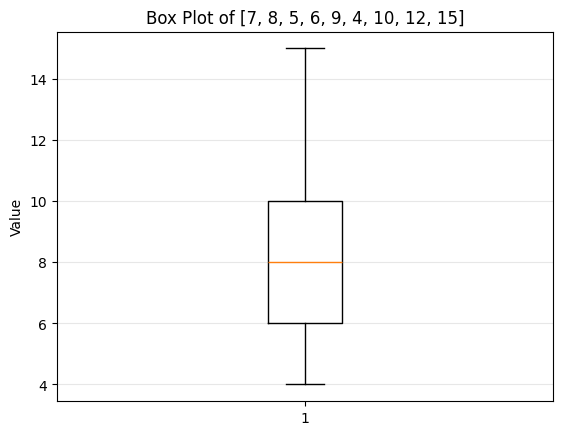

In [31]:
# Box Plot
import numpy as np

data = [7, 8, 5, 6, 9, 4, 10, 12, 15]

# The five-number summary, computed directly
q1, q2, q3 = np.percentile(data, [25, 50, 75])
iqr = q3 - q1
print('sorted        :', sorted(data))
print('Q1 / Q2 / Q3  :', q1, q2, q3)
print('IQR           :', iqr)
print('outlier fences: %.1f to %.1f' % (q1 - 1.5 * iqr, q3 + 1.5 * iqr))

plt.boxplot(data)
plt.ylabel('Value')
plt.title('Box Plot of [7, 8, 5, 6, 9, 4, 10, 12, 15]')
plt.grid(axis='y', alpha=0.3)
plt.show()


### 7.2 Outliers, and a horizontal box plot

**Definition.** Passing a **list of lists** draws one box per dataset on shared axes — the main
reason to use box plots at all. Any value beyond `Q1 − 1.5×IQR` or `Q3 + 1.5×IQR` is drawn as a
separate marker called a **flier**.

**Usage**

```python
plt.boxplot([group_a, group_b], tick_labels=['A', 'B'],
            flierprops={'marker': 'o', 'markerfacecolor': 'red'},
            vert=False)
```

**Actions in the cell below**
- `[data, with_outlier]` — two datasets, two boxes, one shared value axis so they compare directly.
  The second is identical to the first except for one added value, **30**.
- `tick_labels=[...]` — names beside each box. In Matplotlib < 3.9 this argument was called
  `labels=`; it was renamed, so older tutorials show the old spelling.
- `patch_artist=True` + `boxprops` — fill the boxes light blue (see 7.1 on why `patch_artist` is
  required).
- `medianprops` — the red median line, `linewidth=2`.
- `flierprops={'marker': 'o', 'markerfacecolor': 'red', 'markersize': 8}` — style the outlier
  markers so they're unmistakable.
- `vert=False` — **lay the boxes out horizontally**. Values now run along the **x**-axis and the
  category labels sit down the **y**-axis. Horizontal is the better choice when group names are
  long, since they get read left-to-right instead of being rotated.

**What the comparison shows.** The added 30 lands beyond the upper fence, so it's drawn as a lone
red dot rather than being absorbed into the whisker — and the box itself barely moves (Q1 6 → 6.25,
median 8 → 8.5, Q3 10 → 11.5). This is the key property: **box plots are robust**. One extreme
value shifts the quartiles slightly where it would drag a mean noticeably, which is why a box plot
is a standard first look at unfamiliar data — it flags suspicious values instead of quietly
averaging them in.

**Two consequences of `vert=False` in this cell**
1. `plt.ylabel('Value')` now labels the **wrong axis** — with horizontal boxes the values are on x.
   It should be `plt.xlabel('Value')`.
2. `plt.grid(axis='y', ...)` likewise draws lines along the *category* axis rather than across the
   value scale. For a horizontal box plot use `plt.grid(axis='x', alpha=0.3)`.

**Deprecation note:** on Matplotlib 3.10 `vert=` emits a `PendingDeprecationWarning` — it's being
replaced by `orientation=`. The forward-compatible spelling is:

```python
plt.boxplot([data, with_outlier], orientation='horizontal')
```


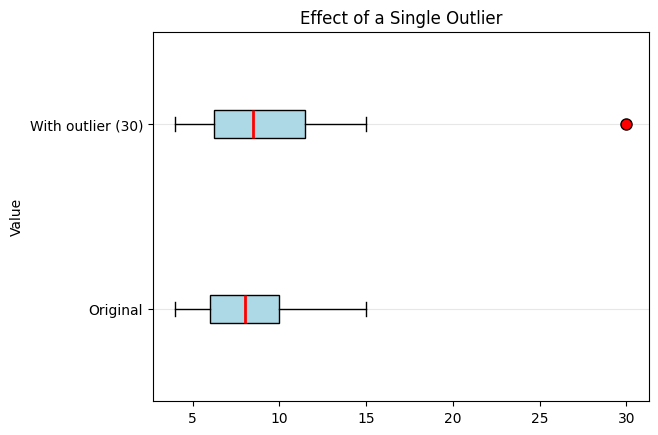

In [33]:
# Outliers, and comparing groups side by side
data = [7, 8, 5, 6, 9, 4, 10, 12, 15]
with_outlier = data + [30]   # one extreme value added

plt.boxplot([data, with_outlier],
            tick_labels=['Original', 'With outlier (30)'],
            patch_artist=True,
            boxprops={'facecolor': 'lightblue', 'edgecolor': 'black'},
            medianprops={'color': 'red', 'linewidth': 2},
            flierprops={'marker': 'o', 'markerfacecolor': 'red', 'markersize': 8},vert=False)

plt.ylabel('Value')
plt.title('Effect of a Single Outlier')
plt.grid(axis='y', alpha=0.3)
plt.show()


### 7.3 Comparing several groups — `showmeans` and `whis`

**Definition.** The real payoff of box plots: **many distributions, side by side, on one scale**.
Three histograms would need three panels and still be hard to compare; three boxes line up on a
shared axis and their centres and spreads can be read against each other directly.

**Usage**

```python
plt.boxplot([g1, g2, g3], tick_labels=['Group 1', 'Group 2', 'Group 3'],
            showmeans=True, whis=1.2)
```

| Parameter | Effect |
| --- | --- |
| `showmeans=True` | draw the **mean** as a triangle marker, alongside the median line |
| `whis=1.2` | shrink the fences from the default `1.5 × IQR` to `1.2 × IQR` |
| `meanline=True` | draw the mean as a dashed line instead of a marker |

**Actions in the cell below**
- Three synthetic groups from `np.random.normal(loc, scale, 100)` — same size, deliberately
  different centres and spreads:

  | | Mean (`loc`) | Spread (`scale`) | Expected box |
  | --- | --- | --- | --- |
  | Group 1 | 50 | 10 | lowest, narrowest |
  | Group 2 | 60 | 15 | highest centre |
  | Group 3 | 55 | 20 | middle centre, **widest** |

- `showmeans=True` — the triangle is the mean, the line is the median. **Comparing the two is
  informative:** they coincide on symmetric data, and separate when the data is skewed or has
  outliers — the mean gets pulled toward the tail, the median doesn't.
- `whis=1.2` — a **tighter** outlier rule than the default 1.5, so more points get flagged as
  fliers. Raising it (`whis=3`) flags fewer. `whis` is a convention, not a law: 1.5 is merely the
  most common choice, and changing it changes which points *look* like outliers without changing
  the data at all — so state the value you used.
- `plt.grid(axis='y', alpha=0.3)` — correct here, since these boxes are vertical.

**What to look for:** Group 2's box sits highest, and Group 3's box is visibly the tallest — that
height *is* the IQR, the spread of the middle 50%. Reading spread straight off the box is something
a bar chart of means cannot do at all.

**Note — no seed.** `np.random.normal` is called without `np.random.seed()`, so **this chart is
different on every run** and the exact outliers change each time. That's fine for a demo of shape,
but add `np.random.seed(42)` (as in the histogram section) whenever the output should be
reproducible.


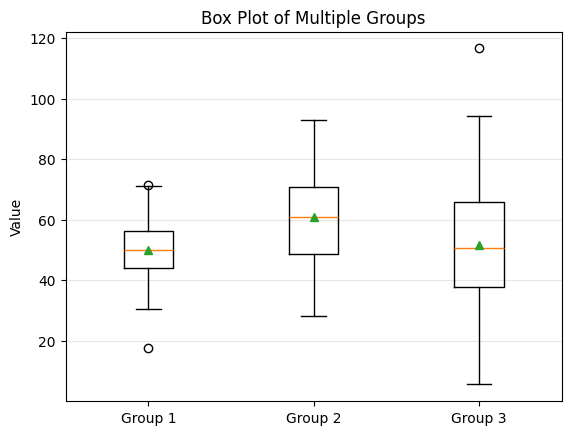

In [34]:
# boxplot with multiple groups
group1 = np.random.normal(loc=50, scale=10, size=100)
group2 = np.random.normal(loc=60, scale=15, size=100)
group3 = np.random.normal(loc=55, scale=20, size=100)

plt.boxplot([group1, group2, group3],
            tick_labels=['Group 1', 'Group 2', 'Group 3'],
            showmeans=True,
            whis=1.2
            )

plt.ylabel('Value')
plt.title('Box Plot of Multiple Groups')
plt.grid(axis='y', alpha=0.3)
plt.show()

---
## 8. Stack Plot (Stacked Area Chart)

**Definition.** A stack plot draws several series **piled on top of one another** as filled bands,
so the top edge of the stack is the **running total**. It answers two questions in one picture:

1. **How did the total change?** — read the height of the whole stack.
2. **How did the composition change?** — read the thickness of each band.

Think of it as *a pie chart at every x position*, or equivalently a line chart whose series are
cumulative rather than independent.

**Usage**

```python
plt.stackplot(x, series1, series2, series3,
              labels=['A', 'B', 'C'], colors=[...])
plt.legend(loc='upper left')
```

| Parameter | Meaning |
| --- | --- |
| `x` | the shared x values — one list, used by every series |
| `*args` | the series themselves, as separate arguments **or** one list of lists |
| `labels` | one name per series, for the legend |
| `colors` | one colour per series, in stacking order |
| `alpha` | band transparency |
| `baseline` | `'zero'` (default), `'sym'`, `'wiggle'`, `'weighted_wiggle'` — where the stack is anchored |

**Stacking order is bottom-up:** the first series passed sits at the bottom, the next rests on it,
and so on. That matters, because the **bottom band is the only one with a flat baseline** and is
therefore the easiest to read accurately — put the series you most want scrutinised first.

**When to use it — and when not to**

| | |
| --- | --- |
| ✅ Good for | parts that genuinely **sum to a meaningful total** over an ordered axis — traffic by source, revenue by region, energy by fuel type |
| ❌ Bad for | comparing the *individual* series precisely — only the bottom band has a straight baseline, so the others sit on a wavy floor and their shapes are distorted |
| ❌ Bad for | quantities that shouldn't be added (temperatures, percentages of different wholes, averages) |

If the reader's main question is "how does series B compare to series C?", use a plain multi-line
`plt.plot()` instead. A stack plot is for *the total and its composition*.

**The data:** a week of website visits split across three acquisition channels — Direct, Organic and
Social. These are parts of one total (all visits), tracked over an ordered axis (days), which is
exactly the stack plot case.

| Day | Direct | Organic | Social | **Total** |
| --- | --- | --- | --- | --- |
| Mon | 20 | 15 | 10 | **45** |
| Tue | 35 | 25 | 15 | **75** |
| Wed | 30 | 20 | 12 | **62** |
| Thu | 35 | 30 | 18 | **83** |
| Fri | 27 | 22 | 14 | **63** |
| Sat | 25 | 18 | 11 | **54** |
| Sun | 32 | 28 | 16 | **76** |


### 8.1 Why not just use a pie? — one day's split

**Definition.** This cell defines the week's data, then draws a pie chart of **Monday alone**
(`direct[0]`, `organic[0]`, `social[0]` — the first value of each series). It's the motivating
comparison for the section: a pie can only ever show **one slice of time**.

**Usage**

```python
plt.pie([direct[0], organic[0], social[0]],
        labels=["Direct", "Organic", "Social"], autopct='%1.1f%%')
```

**Actions in the cell below**
- `days`, `direct`, `organic`, `social` — the week's data, defined here and **reused by the next
  cell**, so this cell must be run first.
- `[direct[0], organic[0], social[0]]` — index `0` picks Monday out of each series: 20, 15 and 10.
- `autopct='%1.1f%%'`, `colors=[...]`, `startangle=90`, `shadow=True` — the pie parameters from
  section 6; the same palette is reused in the stack plot so the colours mean the same thing in both
  charts.
- No `plt.show()`, so the cell also echoes the returned wedge objects as its `execute_result`.

**The limitation this exposes.** The pie says Monday was roughly 44% / 33% / 22% Direct / Organic /
Social — and nothing else. It cannot show that Thursday's total was nearly **double** Monday's, nor
whether Social's share grew over the week. To show composition *and* change over time you would need
seven pies side by side, and comparing angles across seven circles is hopeless.

**That's the gap a stack plot fills:** one chart, all seven days, both the total and the split.


([<matplotlib.patches.Wedge at 0x74b984339810>,
 [Text(-1.0832885061337203, 0.19101312122095906, 'Direct'),
  Text(0.7070662631386209, -0.8426489776479805, 'Organic'),
  Text(0.7070663702780942, 0.8426488877472997, 'Social')],
 [Text(-0.5908846397093019, 0.10418897521143221, '44.4%'),
  Text(0.3856725071665204, -0.4596267150807166, '33.3%'),
  Text(0.38567256560623314, 0.4596266660439816, '22.2%')])

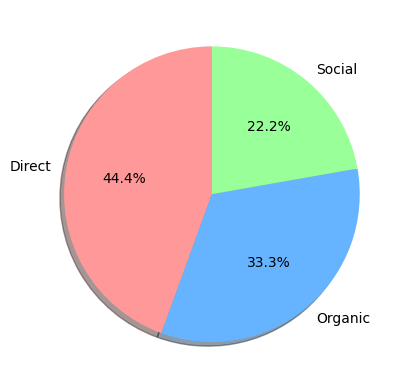

In [35]:
# Stack plot
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
direct = [20, 35, 30, 35, 27, 25, 32]
organic = [15, 25, 20, 30, 22, 18, 28]  
social = [10, 15, 12, 18, 14, 11, 16]

plt.pie([direct[0],organic[0],social[0]],labels=["Direct", "Organic", "Social"],autopct='%1.1f%%', colors=['#ff9999','#66b3ff','#99ff99'], startangle=90, shadow=True)

### 8.2 The stack plot — composition over the whole week

**Definition.** `plt.stackplot()` fills the area between cumulative sums, so the three channels
appear as bands stacked bottom-up and the top edge traces the weekly total.

**Usage**

```python
plt.stackplot(days, direct, organic, social,
              labels=['Direct', 'Organic', 'Social'],
              colors=['#ff9999', '#66b3ff', '#99ff99'])
plt.legend(loc='upper left')
```

**Actions in the cell below**
- `plt.stackplot(days, direct, organic, social, ...)` — one shared x (`days`) followed by the three
  series as separate arguments. Direct is passed first, so it forms the **bottom** band.
- `labels=[...]` — one name per series, in the same order.
- `colors=[...]` — the same three hex colours as the pie in 8.1, so Direct is pink in both charts.
  Keeping a palette consistent across charts of the same data is what lets a reader move between
  them without re-learning the key.
- `plt.legend(loc='upper left')` — **required** for a stack plot; without it the bands are
  unidentifiable. `loc` pins it to the corner with the least data underneath.
- No `plt.show()`, so the returned list of `PolyCollection` objects is echoed as the cell's
  `execute_result` — add `plt.show()` (or a trailing `;`) to suppress that.

**Reading it.** The top edge is the daily total: 45 → 75 → 62 → **83 (Thursday's peak)** → 63 → 54
(the Saturday dip) → 76. Direct is the thickest band throughout, so it's the largest channel every
day, and all three bands widen and narrow together — traffic rises and falls across all channels at
once rather than shifting between them.

**Two things to fix**
1. `plt.ylabel('Traffic Sources')` names the *categories*, but the y-axis measures **visits**.
   `plt.ylabel('Number of visits')` is what the axis actually shows — and a stacked axis especially
   needs saying, since the number is a cumulative total, not any one series.
2. The pie in 8.1 set `plt.style.use('dark_background')` earlier in the notebook, which is global,
   so these pastel bands may render against a dark background. `plt.style.use('default')` resets it.

**Variation — 100% stacked, for share rather than volume.** Normalise each column by its total and
the top edge becomes a flat 100%, so the chart shows *only* how the mix shifts:

```python
import numpy as np
totals = np.array(direct) + np.array(organic) + np.array(social)
plt.stackplot(days,
              np.array(direct)  / totals * 100,
              np.array(organic) / totals * 100,
              np.array(social)  / totals * 100,
              labels=['Direct', 'Organic', 'Social'])
plt.ylabel('Share of visits (%)')
```

Use the plain version to show volume, the 100% version to show mix. Pick deliberately — they can
tell quite different stories about the same data (traffic doubling while every share stays flat).


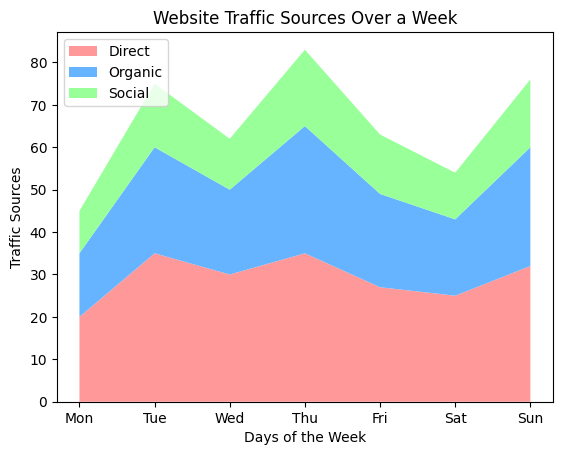

In [36]:
plt.stackplot(days, direct, organic, social, labels=['Direct', 'Organic', 'Social'], colors=['#ff9999','#66b3ff','#99ff99'])
plt.xlabel('Days of the Week')
plt.ylabel('Traffic Sources')
plt.title('Website Traffic Sources Over a Week')
plt.legend(loc='upper left')    

---
## 9. Subplots — several plots in one figure

**Definition.** A subplot is one **Axes** in a grid inside a single **Figure**. Until now every chart
has been drawn on one Axes; subplots divide the canvas so several charts sit side by side and can be
compared without overlapping.

`plt.subplot(nrows, ncols, index)` — the `pyplot` way — creates the grid position at `index` and
makes it the **current axes**, so the `plt.*` calls that follow land there.

**Usage**

```python
plt.subplot(2, 2, 1)      # 2x2 grid, first cell
plt.plot(x, y1)
plt.title('...')

plt.subplot(2, 2, 2)      # move to the second cell
plt.plot(x, y2)

plt.tight_layout()        # stop the titles and labels colliding
```

**`index` counts from 1**, left to right then top to bottom — not from 0 like a Python list:

```
+---+---+
| 1 | 2 |
+---+---+
| 3 | 4 |
+---+---+
```

**Actions in the cell below**
- `y1 … y4` — four transformations of the same `x` (square root, double, square, cube), built with
  list comprehensions. `np.sqrt` needs the `numpy` import from earlier in the notebook.
- Four `plt.subplot(2, 2, i)` calls, each followed by its own `plt.plot()` and `plt.title()`. Every
  `plt.*` call applies to whichever subplot was selected last — the same "current axes" state as
  everywhere else in `pyplot`, now switched deliberately.
- Format strings `'r-o'`, `'g-o'`, `'b-o'`, `'y-o'` — the section 2 shorthand, one colour per panel.
- `plt.tight_layout()` — **essential with subplots.** Panels are packed tightly by default, so
  titles and tick labels overlap their neighbours without it.

**Why the four curves need separate panels:** cube reaches 1000 while square root stays under 4. On
shared axes the square root line would be flat against the bottom — the grid gives each its own
y-scale.

**`subplot` vs `subplots`** — easy to confuse:

| | |
| --- | --- |
| `plt.subplot(2, 2, 1)` | singular; creates **one** panel and selects it; call it repeatedly |
| `plt.subplots(2, 2)` | plural; creates **all** panels at once and returns `(fig, ax)` |

The plural form is the modern one, and is the subject of the next section.


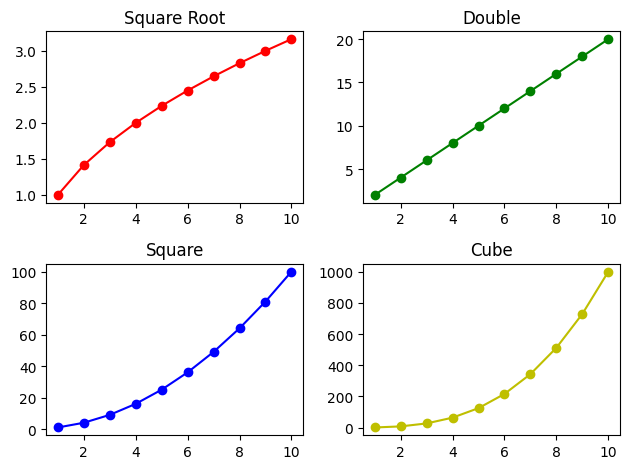

In [37]:
#Sub plot
#- Subplots allow you to create multiple plots in a single figure, arranged in a grid layout. This is useful for comparing different datasets or visualizations side by side.

#plt.subplot(nrows, ncols, index) is used to create subplots in a grid layout. The parameters nrows and ncols specify the number of rows and columns in the grid, while index specifies the position of the subplot within the grid (counting from left to right, top to bottom).

x = [1, 2, 3,4,5,6,7,8,9,10]
y1 = [np.sqrt(i) for i in x]
y2 = [2*i for i in x]
y3 = [i**2 for i in x]
y4 = [i**3 for i in x]

plt.subplot(2, 2, 1)
plt.plot(x, y1, 'r-o')
plt.title('Square Root')

plt.subplot(2, 2, 2)
plt.plot(x, y2, 'g-o')
plt.title('Double')

plt.subplot(2, 2, 3)
plt.plot(x, y3, 'b-o')
plt.title('Square')

plt.subplot(2, 2, 4)
plt.plot(x, y4, 'y-o')
plt.title('Cube')

plt.tight_layout()  # Adjusts the spacing between subplots to prevent overlap


---
## 10. Modern Matplotlib — the Object-Oriented API

**Definition.** The object-oriented (OO) API drops the hidden "current figure" and hands you the
objects directly: `plt.subplots()` returns a **Figure** and its **Axes**, and you call methods on
them. It is the interface the Matplotlib docs recommend for anything beyond a quick one-off chart.

**Usage**

```python
fig, ax = plt.subplots(nrows, ncols, figsize=(8, 6))
ax[0][0].plot(x, y)
ax[0][0].set_title('...')
fig.tight_layout()
```

**The translation is mechanical** — `plt.foo()` becomes `ax.set_foo()` for anything that *sets* a
property, and `ax.foo()` for anything that *draws*:

| `pyplot` | Object-oriented |
| --- | --- |
| `plt.plot(...)` | `ax.plot(...)` |
| `plt.title('t')` | `ax.set_title('t')` |
| `plt.xlabel('x')` | `ax.set_xlabel('x')` |
| `plt.ylim(0, 10)` | `ax.set_ylim(0, 10)` |
| `plt.xticks(p, l)` | `ax.set_xticks(p)`, `ax.set_xticklabels(l)` |
| `plt.legend()` | `ax.legend()` |
| `plt.tight_layout()` | `fig.tight_layout()` |
| `plt.savefig(...)` | `fig.savefig(...)` |

**What `plt.subplots()` returns for `ax` depends on the grid** — this is the single biggest source of
confusion:

| Call | `ax` is | Access a panel with |
| --- | --- | --- |
| `plt.subplots()` | a **single Axes** object | `ax.plot(...)` |
| `plt.subplots(3)` or `plt.subplots(1, 3)` | a **1-D** NumPy array | `ax[i]` |
| `plt.subplots(2, 3)` | a **2-D** NumPy array | `ax[row][col]` |

So `ax[0][0]` on a single-panel figure raises `TypeError: 'Axes' object is not subscriptable` — the
object isn't a grid, so there's nothing to index.

**Why prefer it?** With `pyplot` the target of every call is implicit, so a figure with several
panels becomes a sequence of "which one is current now?" questions. The OO API names its target, and
it's the only way to pass a figure or axes into a function.


### 10.1 A 2×2 grid the object-oriented way

**Definition.** The same four curves as section 9, drawn through explicit Axes objects instead of
`plt.subplot()` calls. `plt.subplots(2, 2)` builds the whole grid in one call and returns it as a
2-D array.

**Usage**

```python
fig, ax = plt.subplots(2, 2, figsize=(8, 6))
ax[0][0].plot(x, y1)
ax[0][0].set_title('Square Root')
fig.tight_layout()
```

**Actions in the cell below**
- `fig, ax = plt.subplots(2, 2, figsize=(8, 6))` — **one** call creates the figure and all four
  Axes. `figsize` is in inches, `(width, height)`, and must be set here — not after the fact.
- `ax[0][0]`, `ax[0][1]`, `ax[1][0]`, `ax[1][1]` — row-then-column indexing, **0-based**, unlike
  `plt.subplot()`'s 1-based `index`. `ax[0, 1]` is the equivalent NumPy spelling.
- `.set_title()` / `.set_xlabel()` / `.set_ylabel()` — the `set_` prefix is the giveaway that you're
  on an Axes rather than in `pyplot`.
- `fig.tight_layout()` — called on the **figure**, since spacing is a property of the whole canvas,
  not of one panel.
- `x`, `y1`…`y4` come from the previous cell, so run section 9 first.

**Compare with section 9.** Identical output, but nothing here depends on which panel happens to be
"current" — each line names the panel it draws on. That's the entire difference, and it's why the
grid stays readable as it grows.

**Repeating four near-identical blocks** is a smell; the loop in 10.3 is the better pattern once the
panels are alike.


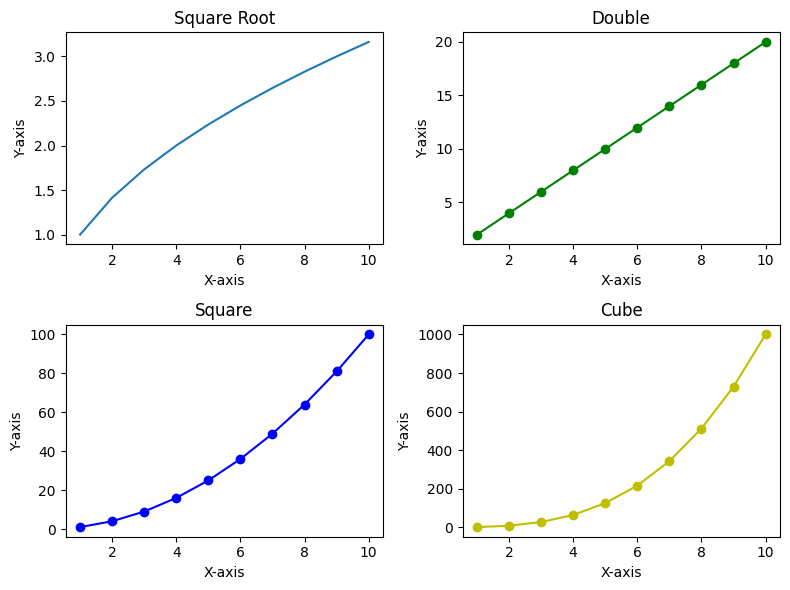

In [38]:
# Modern Matplotlib
#Object oriented API

fig,ax = plt.subplots(2, 2, figsize=(8, 6))
ax[0][0].plot(x, y1)
ax[0][0].set_title('Square Root')
ax[0][0].set_xlabel('X-axis')
ax[0][0].set_ylabel('Y-axis')

ax[0][1].plot(x, y2, 'g-o')
ax[0][1].set_title('Double')
ax[0][1].set_xlabel('X-axis')
ax[0][1].set_ylabel('Y-axis')

ax[1][0].plot(x, y3, 'b-o')
ax[1][0].set_title('Square')    
ax[1][0].set_xlabel('X-axis')
ax[1][0].set_ylabel('Y-axis')

ax[1][1].plot(x, y4, 'y-o')
ax[1][1].set_title('Cube')
ax[1][1].set_xlabel('X-axis')
ax[1][1].set_ylabel('Y-axis')

fig.tight_layout()  # Adjusts the spacing between subplots to prevent overlap


### 10.2 A single Axes with several lines

**Definition.** Called with **no grid arguments**, `plt.subplots()` returns one Figure and one Axes.
This is the standard opening line of most modern Matplotlib code — even for a single chart — because
it names its target from the start.

**Usage**

```python
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(x, y1, label='Square Root')
ax.plot(x, y2, label='Double')
ax.legend()
```

**Actions in the cell below**
- `fig, ax = plt.subplots(figsize=(8, 6))` — no `nrows`/`ncols`, so `ax` is a **single Axes**, used
  as `ax.plot(...)` with no indexing.
- Four `ax.plot(..., label=...)` calls — all four curves on **one** set of axes, layered exactly as
  the multi-line chart in section 1.2 was, but through the Axes object.
- `ax.set_title()` / `.set_xlabel()` / `.set_ylabel()` — the OO equivalents.
- `ax.legend()` — reads the `label=` values. Same rule as `plt.legend()`: labels alone draw nothing.
- No `plt.show()`, so the cell echoes the `Legend` object as its output.

**The `TypeError` trap.** Because `ax` here is one Axes and not an array, `ax[0][0].plot(...)` fails
with `TypeError: 'Axes' object is not subscriptable`. If you index `ax` you must have asked for a
grid — `plt.subplots(2, 2)`, not `plt.subplots()`.

**Worth noticing about the chart itself:** cube dominates the y-axis so severely that square root
and double are pressed flat along the bottom. This is the case *for* the 10.1 grid — when series
share an axis but not a scale, separate panels (or `ax.set_yscale('log')`) beat one crowded plot.


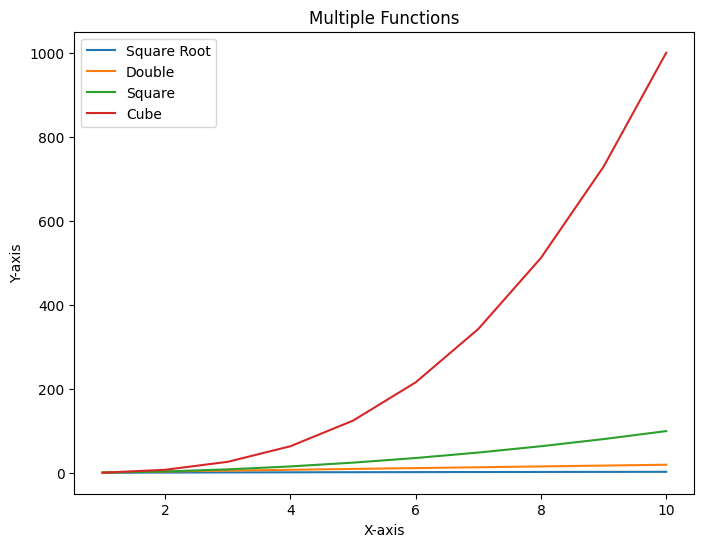

In [39]:
fig,ax = plt.subplots(figsize=(8, 6))
ax.plot(x, y1, label='Square Root')
ax.plot(x, y2, label='Double')
ax.plot(x, y3, label='Square')
ax.plot(x, y4, label='Cube')
ax.set_title('Multiple Functions')
ax.set_xlabel('X-axis')
ax.set_ylabel('Y-axis')
ax.legend()


### 10.3 Task — a grid of city temperatures, sized from the data

**Definition.** The realistic version of a subplot grid: the number of panels isn't hard-coded, it's
**computed from how many items there are**. With a fixed 3 columns, the row count is
`ceil(n_items / 3)`.

**Usage**

```python
from numpy import ceil
r = int(ceil(len(cities) / 3))          # rows needed for 3 columns
fig, ax = plt.subplots(r, 3, figsize=(12, 8))

for i, city in enumerate(cities):
    ax[i // 3][i % 3].plot(days, temperatures[city])
```

**Figure-level labels** — for a grid, the title and axis names usually belong to the whole figure
rather than to each panel:

| Call | Draws |
| --- | --- |
| `fig.suptitle(...)` | one **super-title** above all panels |
| `fig.supxlabel(...)` | one shared x-label under the grid |
| `fig.supylabel(...)` | one shared y-label down the left |

**Actions in the cell below**
- `temperatures` is a **dict** keyed by city, so `temperatures[city]` pulls that city's week.
- `r = int(ceil(len(cities)/3))` — 5 cities over 3 columns needs **2** rows.
- `row = i // 3`, `col = i % 3` — the standard index-to-grid conversion: integer division gives the
  row, the remainder gives the column.
- `ax[row][col].plot(..., marker='o', color='blue')` and `.set_title(city)` — per-panel drawing and
  naming; the per-panel `.grid()` is commented out.
- `fig.suptitle(...)`, `fig.supxlabel(...)`, `fig.supylabel(...)` — one title and one pair of axis
  labels for the whole grid, instead of repeating them on all five panels.
- `fig.tight_layout()` — reflows everything so the super-labels don't overlap the panels.

**Three mistakes this cell is the fixed version of** — each one is a real error worth recognising:

| Attempt | What happens | Fix |
| --- | --- | --- |
| `r = len(cities)//3` | `5//3 = 1` → a 1×3 grid, only 3 panels, then `IndexError` on the 4th city | `ceil`, which **rounds up** |
| `r = ceil(len(cities)/3)` | returns `2.0`, a float → `ValueError: Number of rows must be a positive integer, not 2.0` | wrap in `int(...)` |
| `fig.sup_xlabel(...)` | `AttributeError` — there's no underscore in the real method | `fig.supxlabel(...)` |

**One panel is left blank.** 5 cities in a 2×3 grid fills five of six slots, so `ax[1][2]` renders as
an empty framed box. To remove it:

```python
for extra in ax.flatten()[len(cities):]:
    fig.delaxes(extra)
```

**The `sharey` refinement.** Each panel currently auto-scales its own y-axis, so Chicago's 20–45
range and Phoenix's 70–95 range look identical in shape. Passing `sharey=True` puts every panel on
one scale, which makes the *cities* comparable rather than just their trends — a real choice worth
making deliberately:

```python
fig, ax = plt.subplots(r, 3, figsize=(12, 8), sharex=True, sharey=True)
```


Text(0.02, 0.5, 'Temperature (°F)')

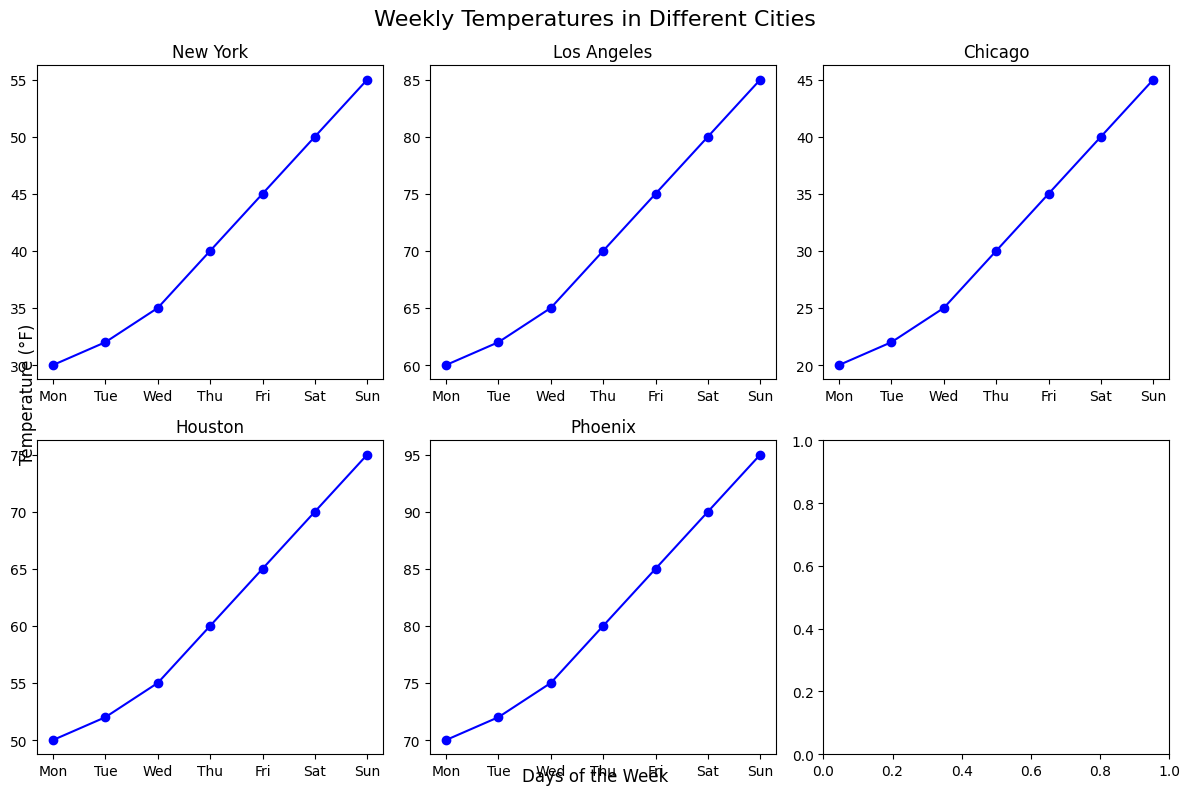

In [40]:
# task
from numpy import ceil


days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
cities = ['New York', 'Los Angeles', 'Chicago', 'Houston', 'Phoenix']

temperatures = {
    'New York': [30, 32, 35, 40, 45, 50, 55],
    'Los Angeles': [60, 62, 65, 70, 75, 80, 85],
    'Chicago': [20, 22, 25, 30, 35, 40, 45],
    'Houston': [50, 52, 55, 60, 65, 70, 75],
    'Phoenix': [70, 72, 75, 80, 85, 90, 95]
}

r = int(ceil(len(cities)/3))

fig, ax = plt.subplots(r,3,figsize=(12, 8))

for i, city in enumerate(cities):
    row = i // 3
    col = i % 3
    ax[row][col].plot(days, temperatures[city], marker='o', color='blue')
    ax[row][col].set_title(city)
    # ax[row][col].grid()

fig.suptitle('Weekly Temperatures in Different Cities', fontsize=16)
fig.tight_layout()  # Adjusts the spacing between subplots to prevent overlap
fig.supxlabel('Days of the Week', fontsize=12)
fig.supylabel('Temperature (°F)', fontsize=12)


### 10.4 `ax.flatten()` — one index instead of two

**Definition.** `plt.subplots(rows, cols)` hands back a 2-D NumPy array, which forces the
`i // 3` / `i % 3` arithmetic of 10.3. `ax.flatten()` returns a **1-D view** of the same Axes in
row-major order, so a single loop counter indexes them directly.

**Usage**

```python
fig, ax = plt.subplots(r, 3, figsize=(12, 8))
ax = ax.flatten()                 # shape (2, 3) -> (6,)

for i, city in enumerate(cities):
    ax[i].plot(days, temperatures[city])
```

**Actions in the cell below**
- `fig, ax = plt.subplots(r, 3, figsize=(12, 8))` — the grid is recreated here, so the cell is
  **self-contained** and can be re-run on its own.
- `ax = ax.flatten()` — reshapes `(2, 3)` to `(6,)`. `ax.ravel()` does the same thing.
- `print(ax)` — echoes the array of six Axes objects, which makes the flattening visible: one flat
  list, ordered left-to-right then top-to-bottom.
- `ax[i]` — no `row`/`col` arithmetic. `enumerate` alone is enough.
- Per-panel `.set_xlabel()` / `.set_ylabel()` / `.grid()` — labels on **every** panel here, rather
  than the figure-level `supxlabel` of 10.3. Repeated on six small panels it's noisy; the figure-level
  version is usually the better choice.

**Why re-running matters.** `flatten()` on an already-flat array is harmless, but a cell containing
*only* `ax = ax.flatten()` breaks on a second run once `ax` has been rebound — which is exactly why
the `plt.subplots(...)` line belongs in the same cell.

**When to use which**

| Situation | Indexing |
| --- | --- |
| Panels laid out meaningfully by row/column (e.g. rows = region, columns = quarter) | `ax[row][col]` — the position carries meaning |
| A flat list of items poured into a grid, as here | `ax.flatten()` then `ax[i]` |

Note the sixth panel is still empty, and `ax.flatten()[len(cities):]` is now the neat way to reach
the leftovers and `fig.delaxes()` them.


[<Axes: > <Axes: > <Axes: > <Axes: > <Axes: > <Axes: >]


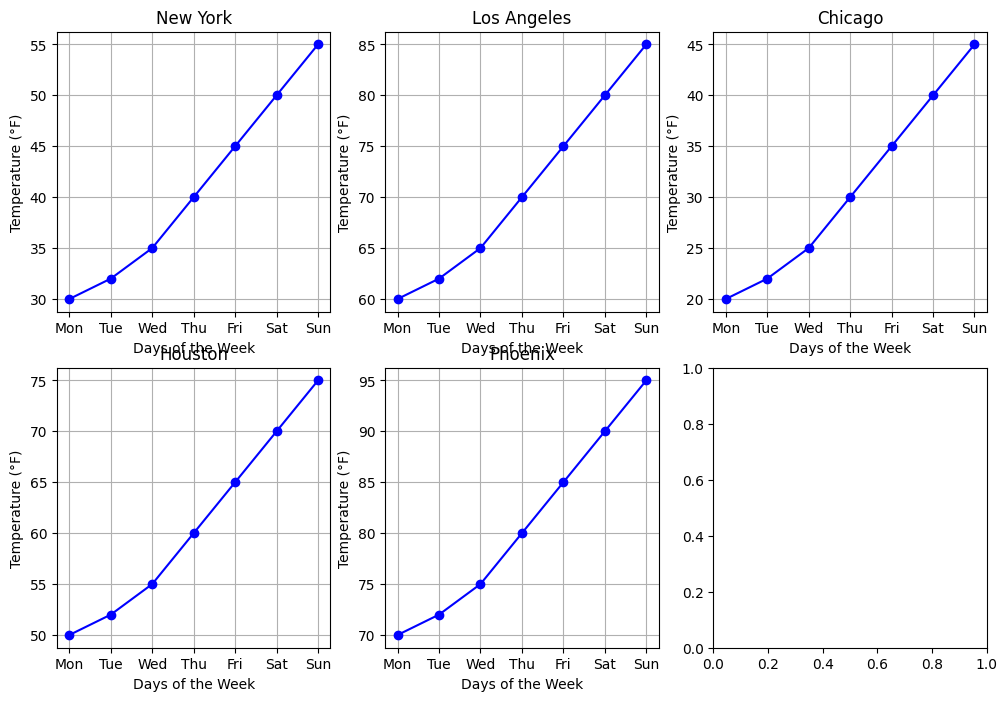

In [41]:
fig, ax = plt.subplots(r,3,figsize=(12, 8))
ax = ax.flatten()  # Flatten the 2D array of axes to 1D for easier iteration
print(ax)
for i, city in enumerate(cities):
    ax[i].plot(days, temperatures[city], marker='o', color='blue')
    ax[i].set_title(city)
    ax[i].set_xlabel('Days of the Week')
    ax[i].set_ylabel('Temperature (°F)')
    ax[i].grid()


---
# Summary / Cheat Sheet

## Creating a chart

| Chart | Call | Input |
| --- | --- | --- |
| Line | `plt.plot(x, y, marker='o')` | paired x/y values |
| Line, shorthand | `plt.plot(x, y, 'o--g')` | `'[marker][line][color]'` |
| Bar | `plt.bar(x, height, width=0.8)` | categories **and** heights |
| Horizontal bar | `plt.barh(y, width)` | better for long labels |
| Grouped bar | `plt.bar(x - w/2, s1, w)` + `plt.bar(x + w/2, s2, w)` | offset positions from `np.arange` |
| Scatter | `plt.scatter(x, y, s=..., alpha=0.7)` | two measurements per point |
| Scatter, colour-mapped | `plt.scatter(x, y, c=vals, cmap='OrRd')` + `plt.colorbar()` | `c=` is numeric |
| Histogram | `plt.hist(data, bins=10, edgecolor='black')` | one list of **raw** values |
| Histogram, custom bins | `plt.hist(data, bins=[0, 18, 30, 45, 60])` | explicit edges |
| Pie | `plt.pie(vals, labels=names, autopct='%1.1f%%')` | parts of one whole |
| Box plot | `plt.boxplot(data, patch_artist=True)` | raw values; quartiles computed for you |
| Box plots, grouped | `plt.boxplot([g1, g2], tick_labels=['A', 'B'])` | a list of lists |
| Stacked area | `plt.stackplot(x, s1, s2, s3, labels=[...])` | series that sum to a total |
| Grid of panels (`pyplot`) | `plt.subplot(2, 2, 1)` … | 1-based index, left→right, top→bottom |
| Grid of panels (OO) | `fig, ax = plt.subplots(2, 2, figsize=(8, 6))` | `ax[row][col]`, 0-based |

## Labelling and annotating

| Task | Call |
| --- | --- |
| Axis labels, title | `plt.xlabel()` · `plt.ylabel()` · `plt.title()` |
| Legend | `label=` on each series **+** `plt.legend(loc='upper left')` |
| Colour scale key | `plt.colorbar(label='...')` |
| Free text at a position | `plt.text(x, y, s, ha='center', va='bottom')` |
| Label a specific point | `plt.annotate(text, xy=(x, y), xytext=(x+.5, y+.5))` |
| …with an arrow | `arrowprops=dict(arrowstyle='->')` |
| Vertical / horizontal marker | `plt.axvline(x, linestyle='--')` · `plt.axhline(y)` |

## Axes, ticks and layout

| Task | Call |
| --- | --- |
| Visible range | `plt.xlim(lo, hi)` · `plt.ylim(lo, hi)` |
| Tick positions and labels | `plt.xticks(positions, labels, rotation=45, ha='right')` |
| Grid | `plt.grid(axis='y', alpha=0.3)` |
| Global style | `plt.style.use('ggplot')` · list them with `plt.style.available` |
| Stop labels being clipped | `plt.tight_layout()` |
| Figure size | `plt.figure(figsize=(10, 5))` — **before** plotting |
| Multiple panels | `fig, ax = plt.subplots(1, 2)` |
| Shared scales across panels | `plt.subplots(r, c, sharex=True, sharey=True)` |
| Flat panel indexing | `ax = ax.flatten()` then `ax[i]` |
| Drop an unused panel | `fig.delaxes(ax.flatten()[-1])` |

## Output

| Task | Call |
| --- | --- |
| Render | `plt.show()` — draws, then **clears** the figure |
| Save | `plt.savefig('f.png', dpi=300, bbox_inches='tight')` — **before** `show()` |

## Figure-level vs Axes-level

Once you hold a `fig` and an `ax`, the `plt.*` calls have direct equivalents:

| `pyplot` | Object-oriented |
| --- | --- |
| `plt.plot()` · `plt.bar()` · `plt.scatter()` | `ax.plot()` · `ax.bar()` · `ax.scatter()` |
| `plt.title()` · `plt.xlabel()` | `ax.set_title()` · `ax.set_xlabel()` |
| `plt.xlim()` · `plt.xticks()` | `ax.set_xlim()` · `ax.set_xticks()` |
| `plt.legend()` · `plt.grid()` | `ax.legend()` · `ax.grid()` |
| `plt.tight_layout()` · `plt.savefig()` | `fig.tight_layout()` · `fig.savefig()` |
| — | `fig.suptitle()` · `fig.supxlabel()` · `fig.supylabel()` (whole-grid labels) |

Rule of thumb: **draw and set on the `ax`, lay out and save on the `fig`.**

## Statistics helpers used

| Task | Call |
| --- | --- |
| Quartiles / percentiles | `np.percentile(data, [25, 50, 75])` |
| Evenly spaced positions | `np.arange(n)` — supports element-wise `± width` |
| Reproducible sample data | `np.random.seed(42)` then `np.random.normal(loc, scale, size)` |

## Choosing a chart

| Your question | Chart |
| --- | --- |
| How does it change over time? | **line** |
| Which category is biggest? | **bar** |
| Do these two measurements move together? | **scatter** |
| How is this one variable spread out? | **histogram** |
| What share of the total is each part? | **pie** (≤ 5–6 slices) |
| How do the spreads compare across groups? | **box plot** |
| How did the total *and* its composition change? | **stack plot** |
| How do I compare several charts at once? | **subplots** |

Two pairs are easy to confuse:

- **Bar vs histogram** — a bar chart takes *categories and heights you supply*; a histogram takes
  *raw values and counts them into bins*. Bars have gaps, histogram bins are adjacent.
- **Pie vs stack plot** — a pie is composition at **one moment**; a stack plot is composition
  **over an axis**. A pie of one column is a single slice of a stack plot.

## Gotchas worth memorising

1. `pyplot` mutates a hidden *current figure*; `plt.show()` renders it **and clears it**.
2. `plt.savefig()` must come **before** `plt.show()`, in the same cell — afterwards you save a blank
   canvas.
3. `plt.style.use()` is **global** and applies from the next figure onward. Set it once, at the top.
4. `label=` alone draws nothing — a legend needs `plt.legend()` as well.
5. Bar charts should start at **y = 0**; a truncated baseline exaggerates differences.
6. Grouping bars is manual: `np.arange` slots, `± width` offsets, then `plt.xticks(x, labels)` to
   put the real labels back. Keep `n_bars × width ≤ 0.8`.
7. On a scatter, `color=` and `c=` are **mutually exclusive** — passing both raises `ValueError`.
   `c=` + `cmap=` also needs a `plt.colorbar()`, or the gradient means nothing.
8. Always give a histogram `edgecolor`, and try several `bins` before trusting the shape.
9. A pie is for parts of **one whole**, with few clearly-different slices — otherwise use bars.
   `explode` and `shadow` make a slice *look* bigger than its angle warrants.
10. A box plot is **five numbers** — min, Q1, median, Q3, max — plus outliers past `1.5 × IQR`.
    Robust to extreme values, but blind to a two-peaked shape; pair it with a histogram.
11. On a stack plot only the **bottom band** has a flat baseline, so it's the wrong chart for
    comparing individual series — use multiple lines for that.
12. Seed the generator (`np.random.seed`) whenever sample data should be reproducible.
13. `plt.subplot()` (singular) makes **one** panel with a **1-based** index; `plt.subplots()`
    (plural) makes **all** of them and returns `(fig, ax)` with **0-based** indexing.
14. What `ax` *is* depends on the grid: a single Axes with no arguments (indexing it raises
    `TypeError: 'Axes' object is not subscriptable`), a 1-D array for one row or column, a 2-D array
    for a real grid. `ax.flatten()` collapses the last case to `ax[i]`.
15. Row counts computed from data need `int(ceil(n/cols))` — floor division under-counts and drops
    panels, and a bare `ceil()` returns a float, which `plt.subplots()` rejects.
16. Always `tight_layout()` a grid, and prefer `fig.suptitle`/`supxlabel`/`supylabel` over repeating
    labels on every panel.
17. Labels, legend and units aren't decoration — an unlabelled axis makes a chart unreadable.

## Where to go next

- **Beyond the basics of the OO API** (sections 9–10) — `fig.add_gridspec()` for panels of
  unequal size, `ax.twinx()` for two y-scales on one panel, and `constrained_layout=True` as a
  smarter alternative to `tight_layout()`.
- **More chart types** — `plt.violinplot()` (a box plot crossed with a distribution curve),
  `plt.fill_between()` (shaded confidence bands), `plt.imshow()` / `plt.pcolormesh()` (heatmaps),
  `plt.errorbar()`.
- **Higher-level wrappers** — `df.plot()` in pandas and `seaborn`, both of which return Matplotlib
  axes, so everything in this cheat sheet still applies on top of them.
